In [72]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the CSV file
df = pd.read_csv('lighting_dataset.csv')

# Quick overview of the dataset
print(df.describe())



          Session       Group        Seat       Trial  Illuminance (lx)  \
count  252.000000  252.000000  252.000000  252.000000        252.000000   
mean     1.857143    3.222222    2.492063    2.500000        305.000000   
std      0.795548    1.650251    1.127321    1.120259        307.653372   
min      1.000000    1.000000    1.000000    1.000000         20.000000   
25%      1.000000    2.000000    1.000000    1.750000         65.000000   
50%      2.000000    3.000000    2.000000    2.500000        200.000000   
75%      3.000000    4.000000    4.000000    3.250000        440.000000   
max      3.000000    7.000000    4.000000    4.000000        800.000000   

         Time (s)  No. of correct answers          Q1          Q2          Q3  \
count  252.000000              252.000000  252.000000  252.000000  252.000000   
mean    43.265556               52.789683    3.325397    3.146825    3.273810   
std      9.020573               12.090603    1.890759    1.686090    1.740206   


In [73]:
print(df)

     Session  Group  Seat  Trial  Illuminance (lx)  Time (s) Contrast  \
0          1      1     1      1               800     46.00     High   
1          1      1     2      1               800     54.78     high   
2          1      1     3      1               800     59.20      low   
3          1      1     4      1               800     56.31      low   
4          1      1     1      2                20     42.80     High   
..       ...    ...   ...    ...               ...       ...      ...   
247        3      4     4      3               320     45.11     High   
248        3      4     1      4                20     26.57      low   
249        3      4     2      4                20     51.06      Low   
250        3      4     3      4                20     33.72     High   
251        3      4     4      4                20     51.12     high   

     No. of correct answers Variation  Q1  Q2  Q3  Q4  
0                        52         C   2   2   3   3  
1          

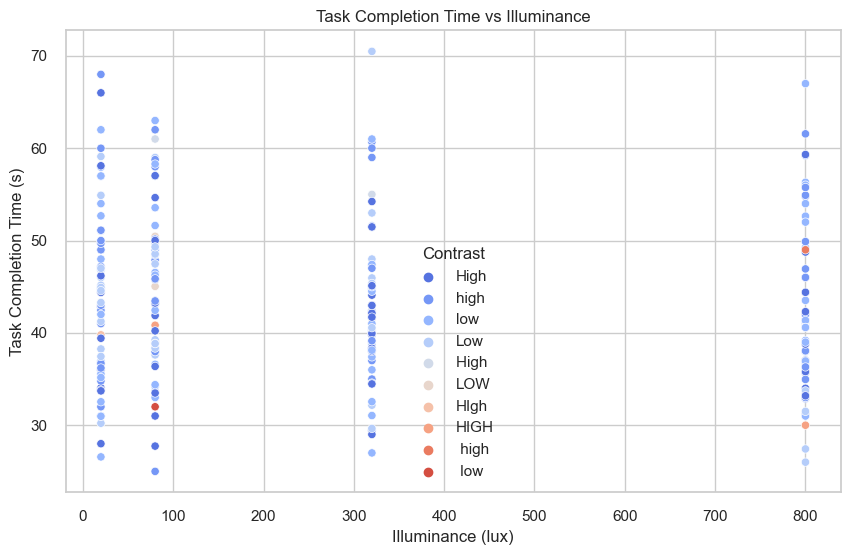

In [74]:
# Plot the relationship between Illuminance and Task Completion Time
plt.figure(figsize=(10,6))
sns.scatterplot(x='Illuminance (lx)', y='Time (s)', hue='Contrast', data=df, palette='coolwarm')
plt.title('Task Completion Time vs Illuminance')
plt.xlabel('Illuminance (lux)')
plt.ylabel('Task Completion Time (s)')
plt.grid(True)
plt.show()

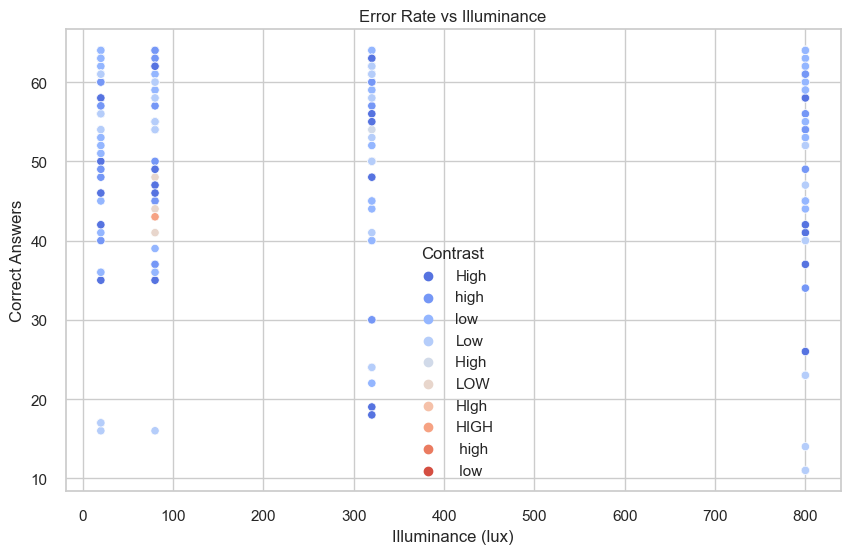

In [75]:
# Plot the relationship between Illuminance and Task performane
plt.figure(figsize=(10,6))
sns.scatterplot(x='Illuminance (lx)', y='No. of correct answers', hue='Contrast', data=df, palette='coolwarm')
plt.title('Illuminance and Task Performance')
plt.xlabel('Illuminance (lux)')
plt.ylabel('Correct Answers')
plt.grid(True)
plt.show()

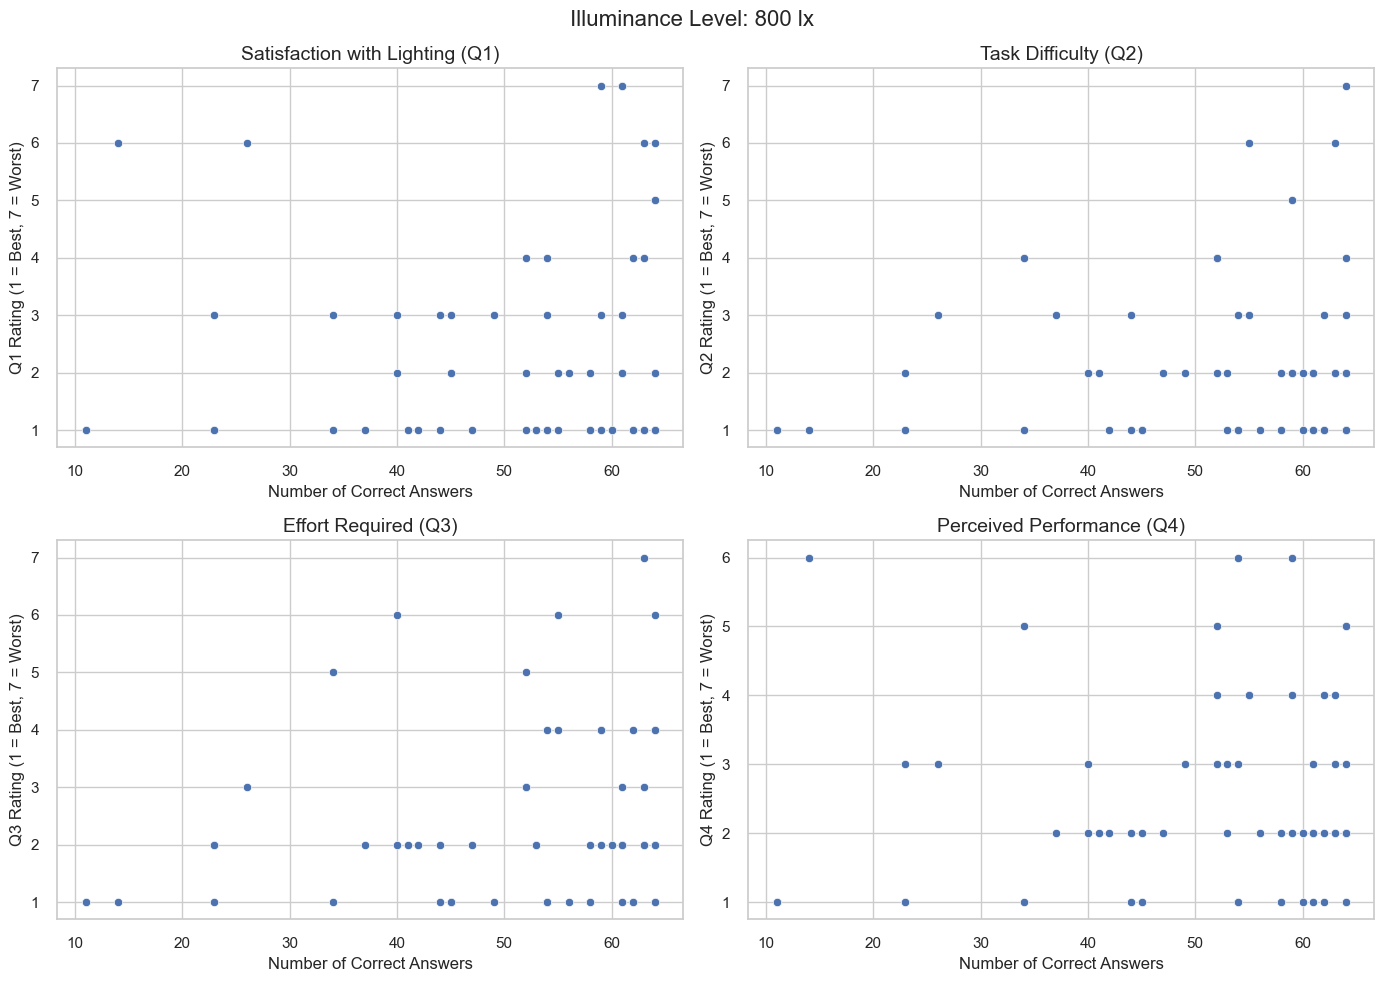

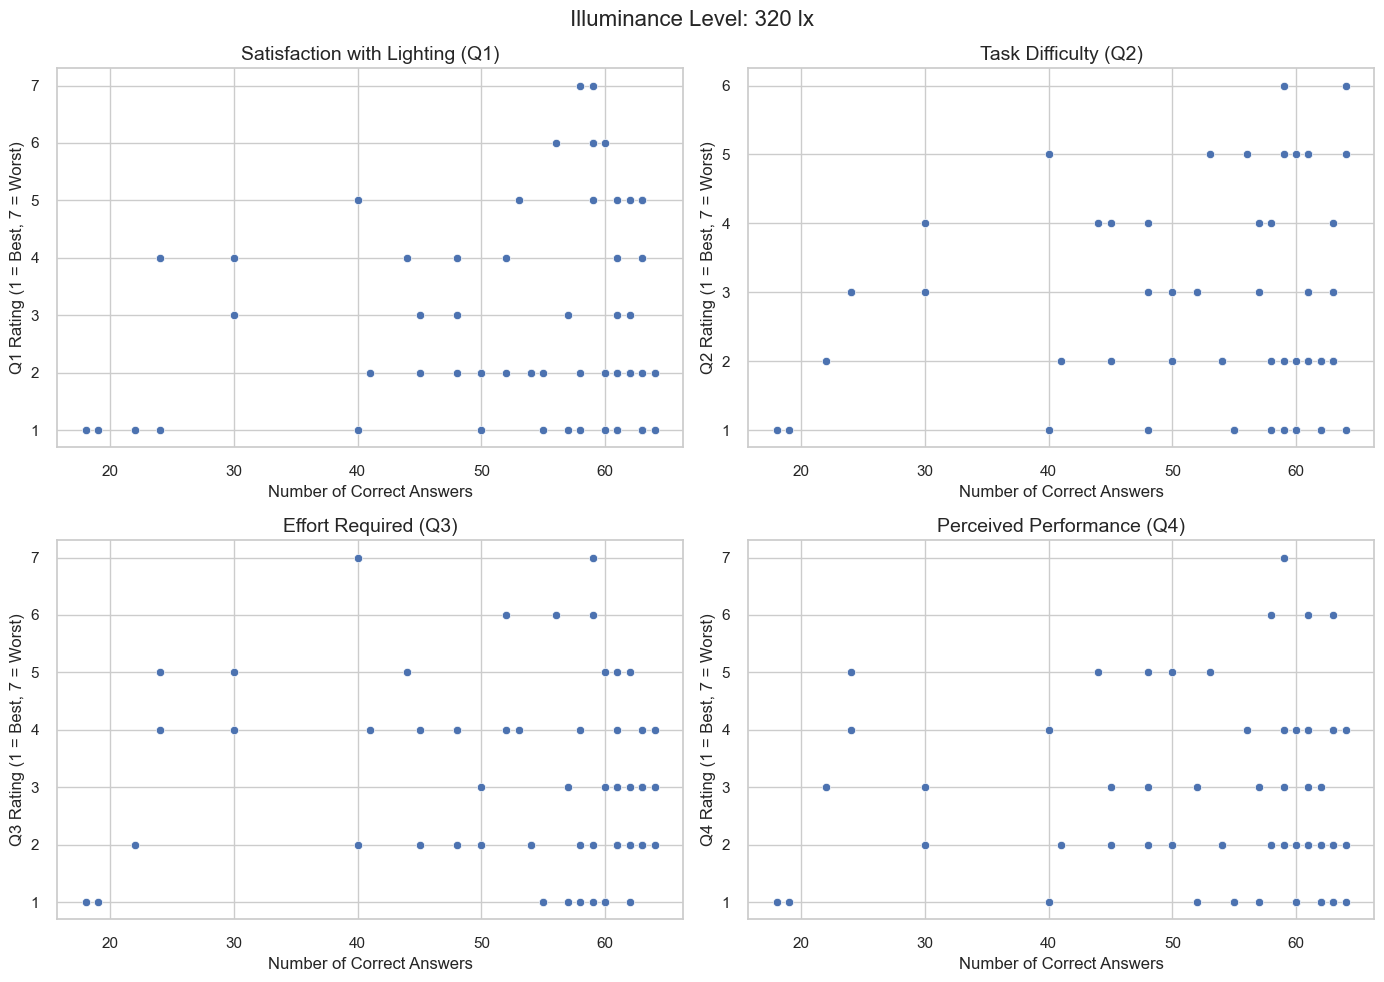

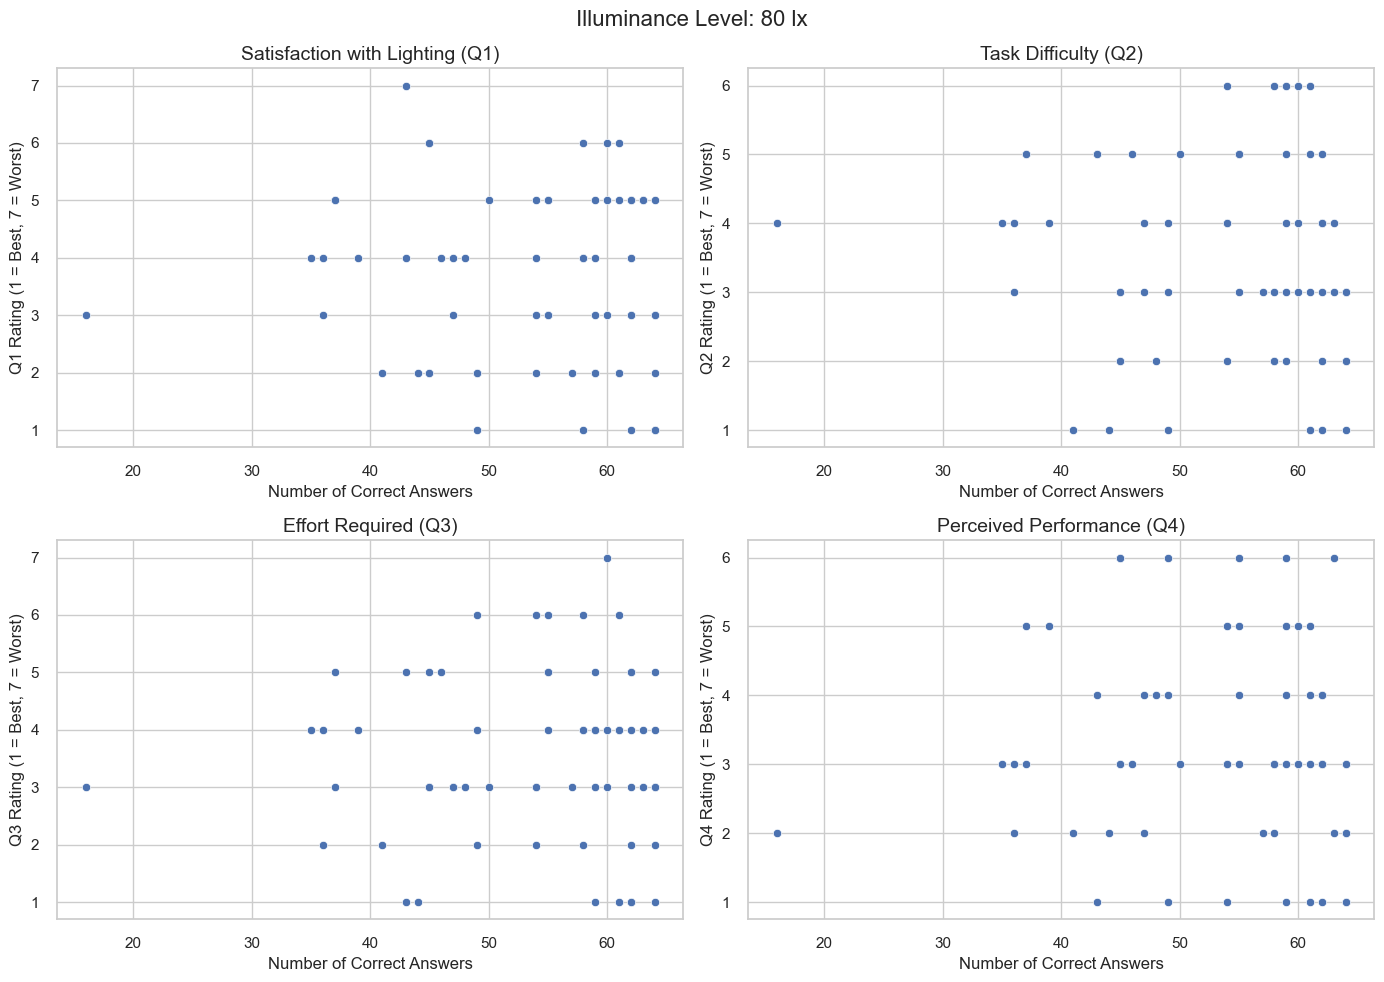

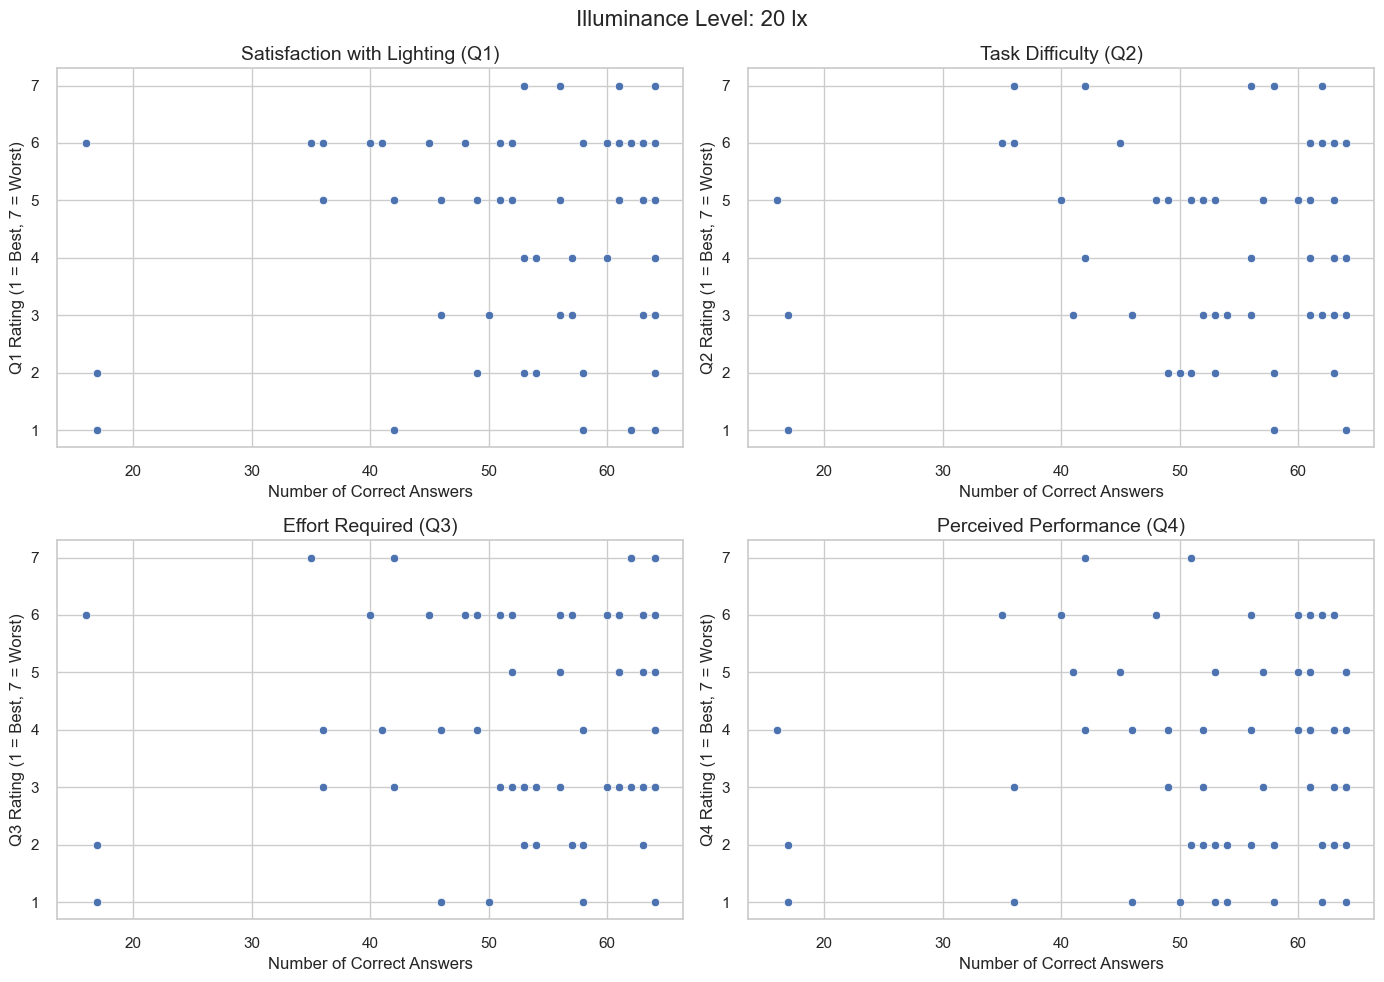

In [76]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for the plots
sns.set(style="whitegrid")

# Create a function to generate plots for each illuminance level
def plot_correct_answers_vs_questions_by_illuminance(df):
    # List of question columns and titles
    questions = ['Q1', 'Q2', 'Q3', 'Q4']
    titles = [
        'Satisfaction with Lighting (Q1)',
        'Task Difficulty (Q2)',
        'Effort Required (Q3)',
        'Perceived Performance (Q4)'
    ]
    
    # List of illuminance levels to filter by
    illuminance_levels = [800, 320, 80, 20]
    
    # Loop through each illuminance level
    for level in illuminance_levels:
        # Filter the dataframe for the current illuminance level
        df_level = df[df['Illuminance (lx)'] == level]
        
        # Set up the figure with 4 subplots
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        fig.suptitle(f'Illuminance Level: {level} lx', fontsize=16)
        fig.subplots_adjust(hspace=0.4, wspace=0.4)
        
        # Flatten the axes array for easy indexing
        axes = axes.flatten()
        
        # Loop through each question and create a scatter plot
        for i, question in enumerate(questions):
            sns.scatterplot(x=df_level['No. of correct answers'], y=df_level[question], ax=axes[i], color="b")
            axes[i].set_title(titles[i], fontsize=14)
            axes[i].set_xlabel('Number of Correct Answers', fontsize=12)
            axes[i].set_ylabel(f'{question} Rating (1 = Best, 7 = Worst)', fontsize=12)
        
        # Show the plot for this illuminance level
        plt.tight_layout()
        plt.show()

# Call the function to generate the plots
plot_correct_answers_vs_questions_by_illuminance(df)


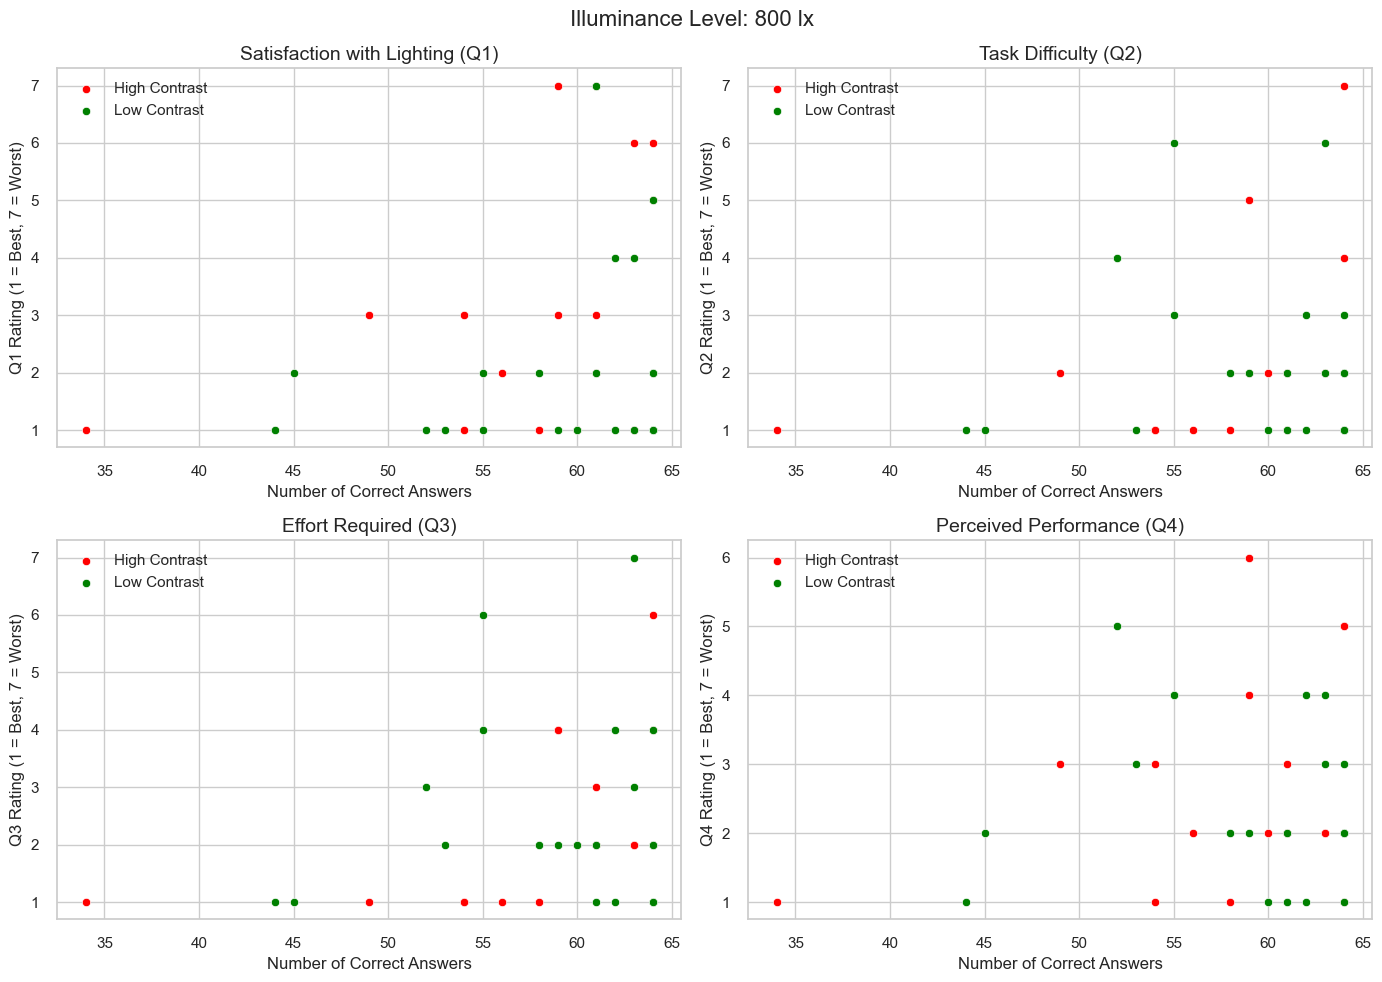

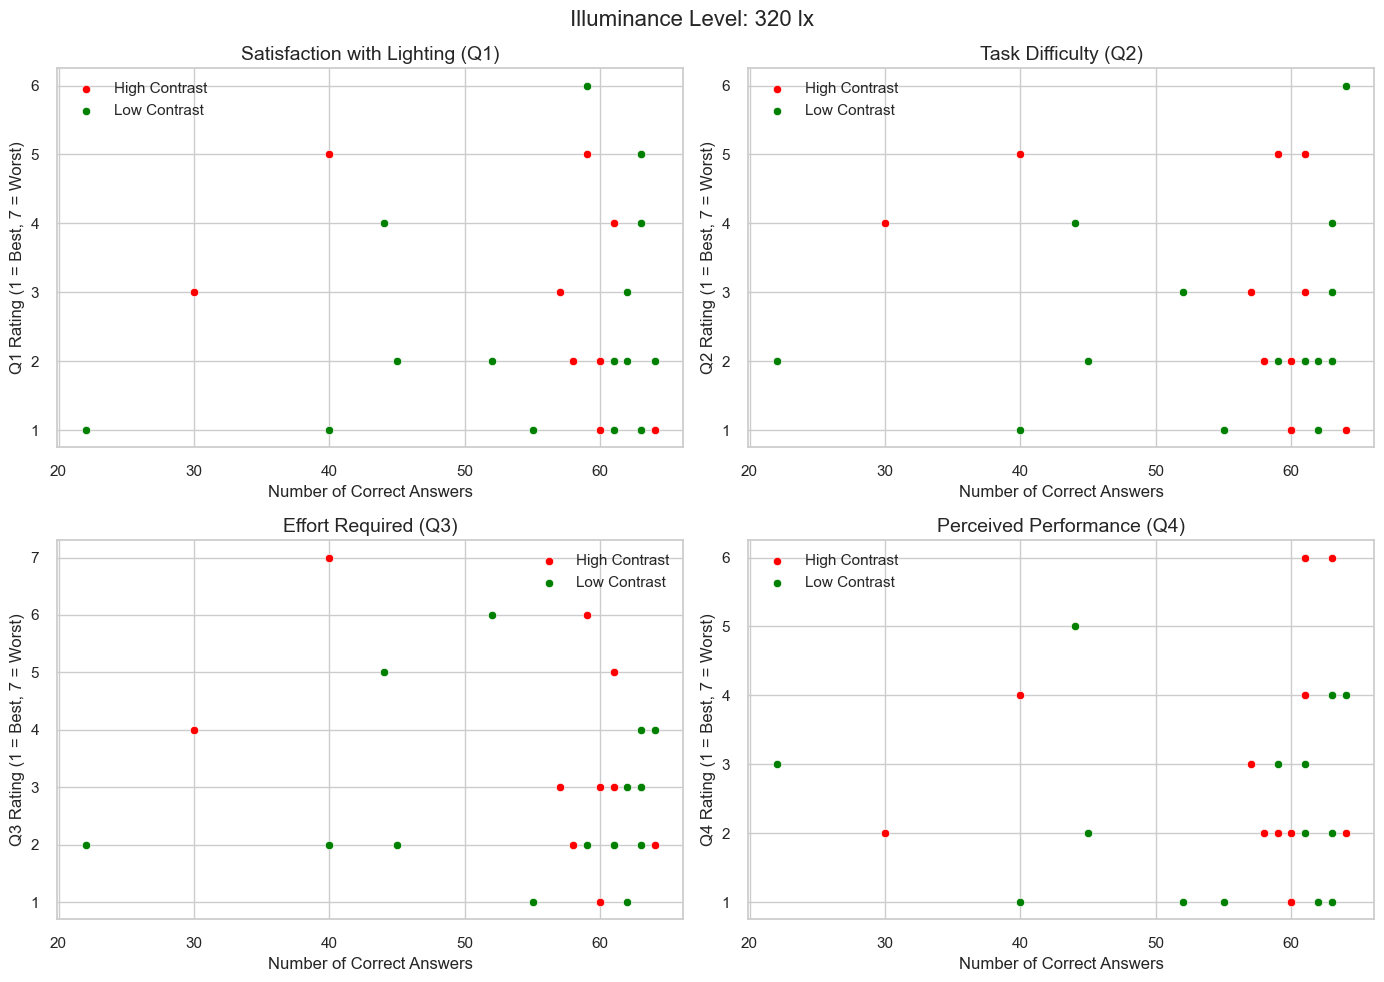

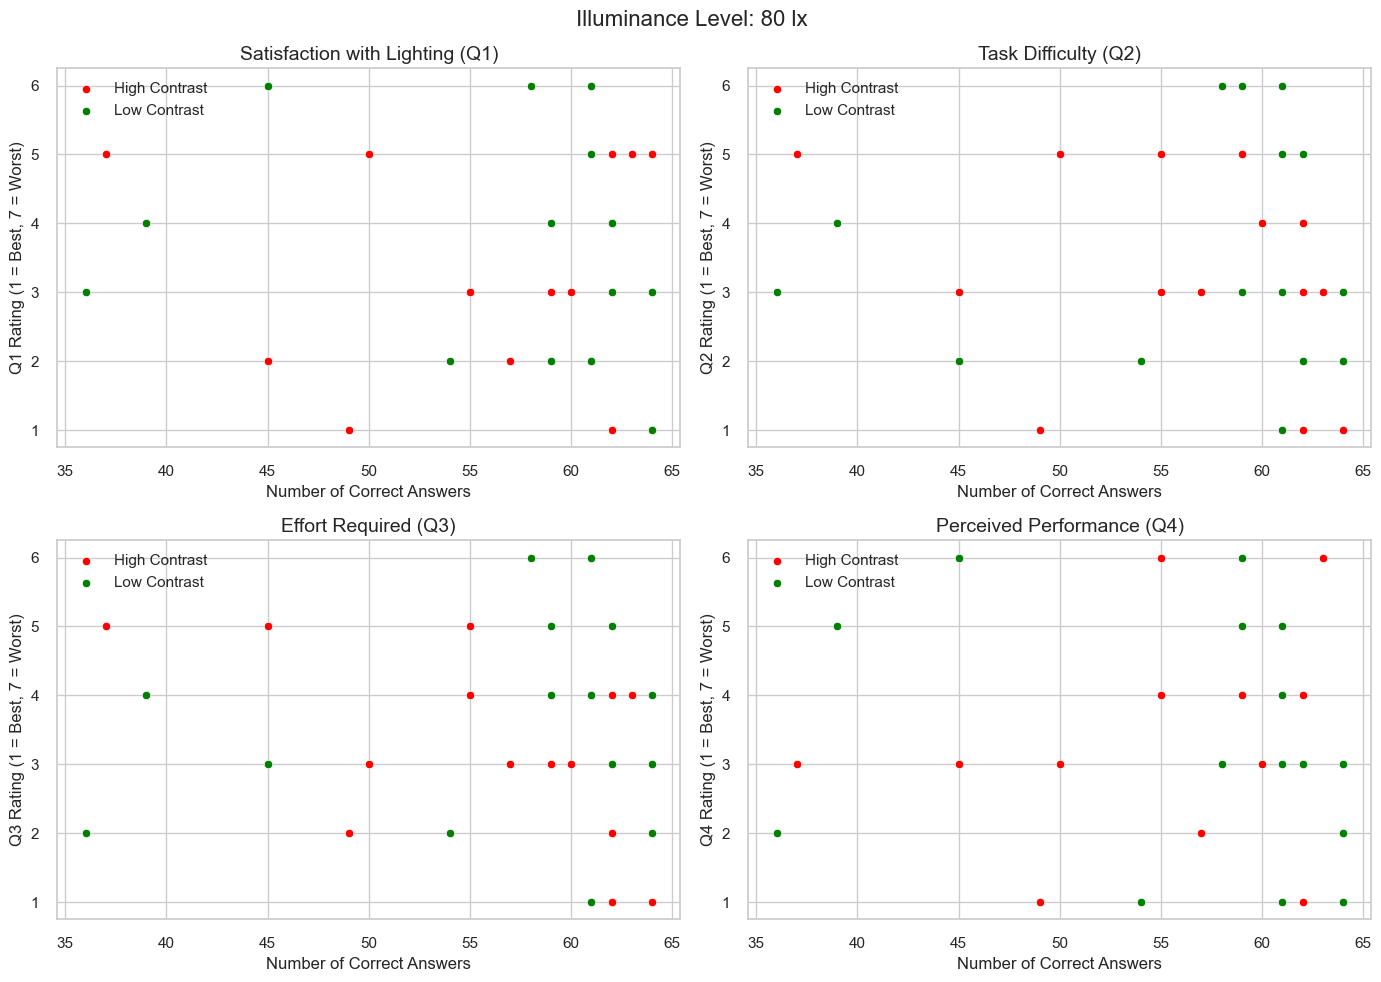

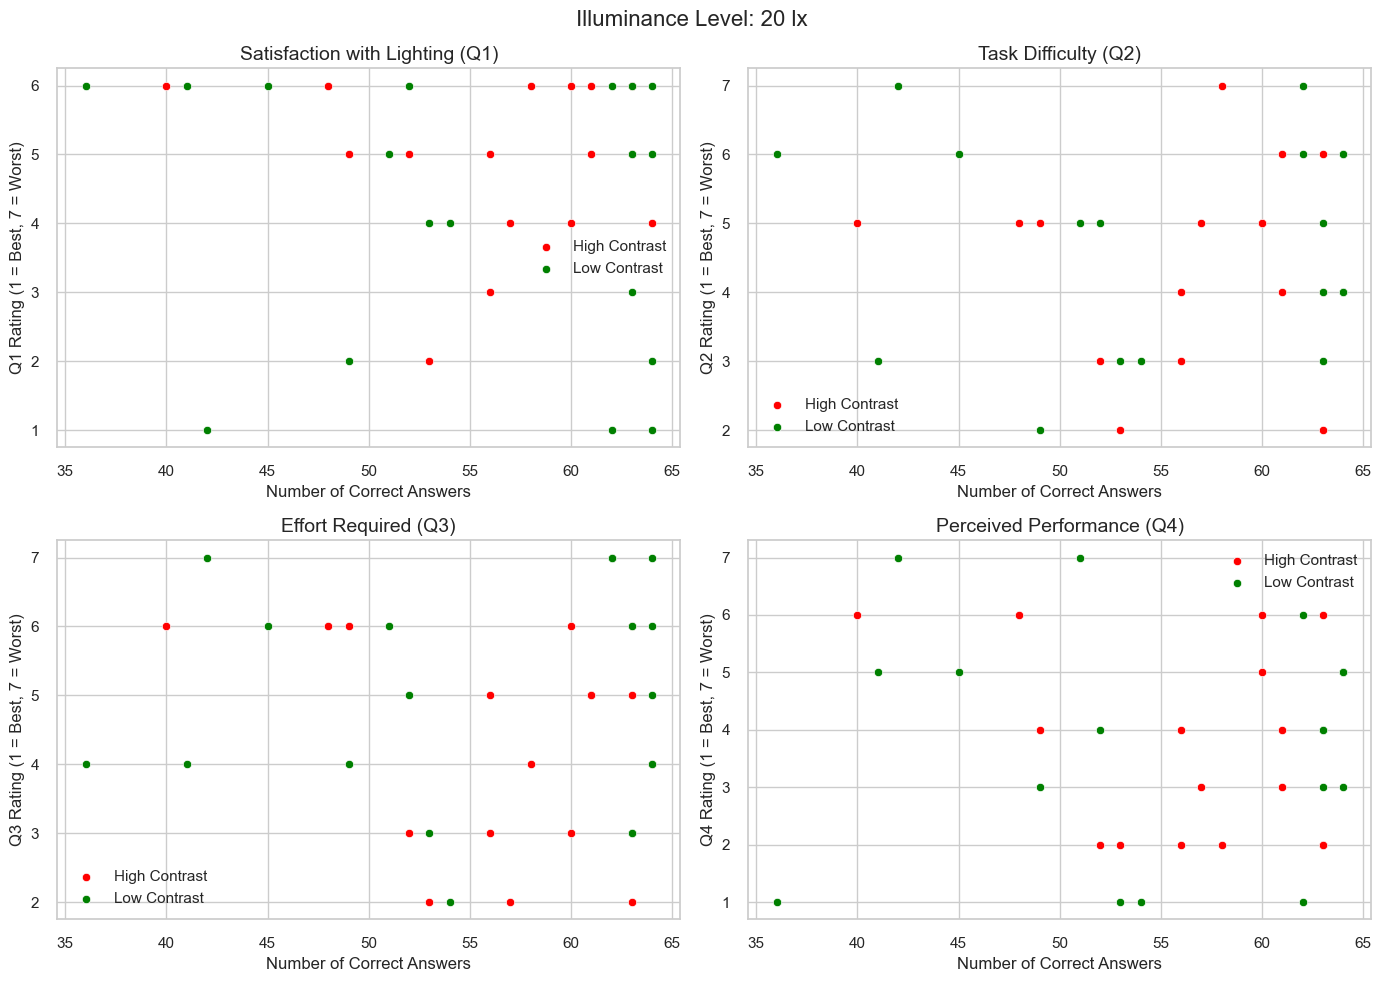

In [77]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for the plots
sns.set(style="whitegrid")

# Create a function to generate plots for each illuminance level with contrast filtering
def plot_correct_answers_vs_questions_by_illuminance_and_contrast(df):
    # List of question columns and titles
    questions = ['Q1', 'Q2', 'Q3', 'Q4']
    titles = [
        'Satisfaction with Lighting (Q1)',
        'Task Difficulty (Q2)',
        'Effort Required (Q3)',
        'Perceived Performance (Q4)'
    ]
    
    # List of illuminance levels to filter by
    illuminance_levels = [800, 320, 80, 20]
    
    # Loop through each illuminance level
    for level in illuminance_levels:
        # Filter the dataframe for the current illuminance level
        df_level = df[df['Illuminance (lx)'] == level]
        
        # Set up the figure with 4 subplots
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        fig.suptitle(f'Illuminance Level: {level} lx', fontsize=16)
        fig.subplots_adjust(hspace=0.4, wspace=0.4)
        
        # Flatten the axes array for easy indexing
        axes = axes.flatten()
        
        # Loop through each question and create a scatter plot
        for i, question in enumerate(questions):
            # Plot high contrast points in red
            sns.scatterplot(
                x=df_level[df_level['Contrast'] == 'high']['No. of correct answers'],
                y=df_level[df_level['Contrast'] == 'high'][question],
                ax=axes[i], color="red", label='High Contrast'
            )
            
            # Plot low contrast points in green
            sns.scatterplot(
                x=df_level[df_level['Contrast'] == 'low']['No. of correct answers'],
                y=df_level[df_level['Contrast'] == 'low'][question],
                ax=axes[i], color="green", label='Low Contrast'
            )
            
            axes[i].set_title(titles[i], fontsize=14)
            axes[i].set_xlabel('Number of Correct Answers', fontsize=12)
            axes[i].set_ylabel(f'{question} Rating (1 = Best, 7 = Worst)', fontsize=12)
            axes[i].legend(loc='best')
        
        # Save the plot as an SVG file
        plt.tight_layout()
        filename = f'Illuminance_{level}_lx_plots.svg'
        plt.savefig(filename, format='svg')  # Save plot as SVG
        
        # Show the plot for this illuminance level
        plt.show()

# Call the function to generate the plots
plot_correct_answers_vs_questions_by_illuminance_and_contrast(df)


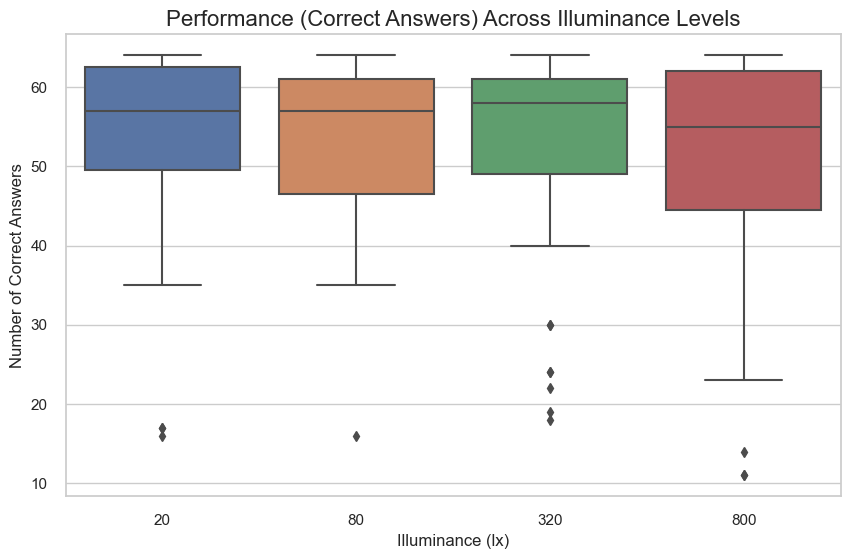

In [78]:
# Box plot for number of correct answers by illuminance level
plt.figure(figsize=(10, 6))
sns.boxplot(x='Illuminance (lx)', y='No. of correct answers', data=df)
plt.title('Performance (Correct Answers) Across Illuminance Levels', fontsize=16)
plt.xlabel('Illuminance (lx)', fontsize=12)
plt.ylabel('Number of Correct Answers', fontsize=12)
plt.show()


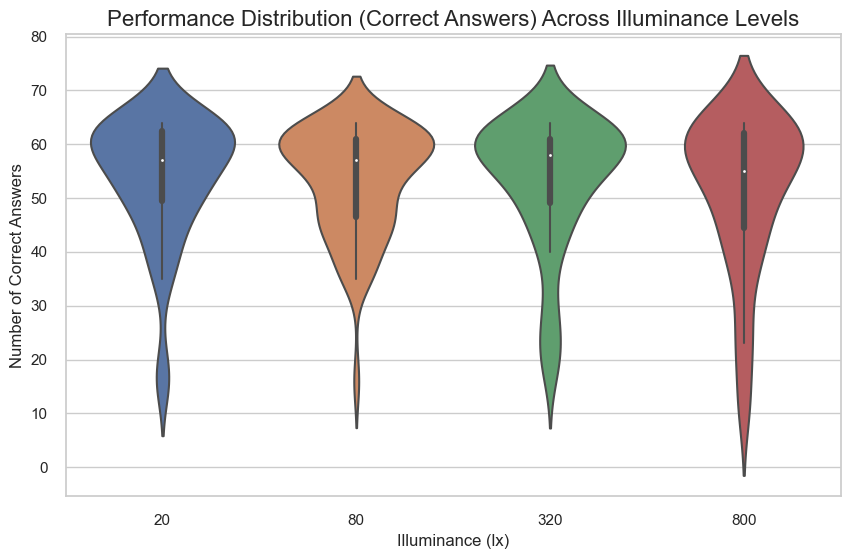

In [79]:
# Violin plot for number of correct answers by illuminance level
plt.figure(figsize=(10, 6))
sns.violinplot(x='Illuminance (lx)', y='No. of correct answers', data=df)
plt.title('Performance Distribution (Correct Answers) Across Illuminance Levels', fontsize=16)
plt.xlabel('Illuminance (lx)', fontsize=12)
plt.ylabel('Number of Correct Answers', fontsize=12)
plt.show()


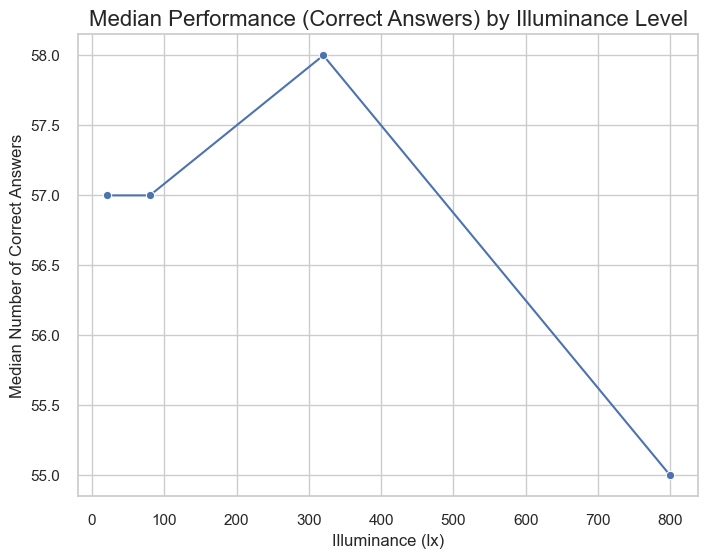

In [80]:
# Calculate mean correct answers for each illuminance level
median_performance = df.groupby('Illuminance (lx)')['No. of correct answers'].median()

# Line plot of average performance by illuminance level
plt.figure(figsize=(8, 6))
sns.lineplot(x=median_performance.index, y=median_performance.values, marker='o')
plt.title('Median Performance (Correct Answers) by Illuminance Level', fontsize=16)
plt.xlabel('Illuminance (lx)', fontsize=12)
plt.ylabel('Median Number of Correct Answers', fontsize=12)
plt.show()


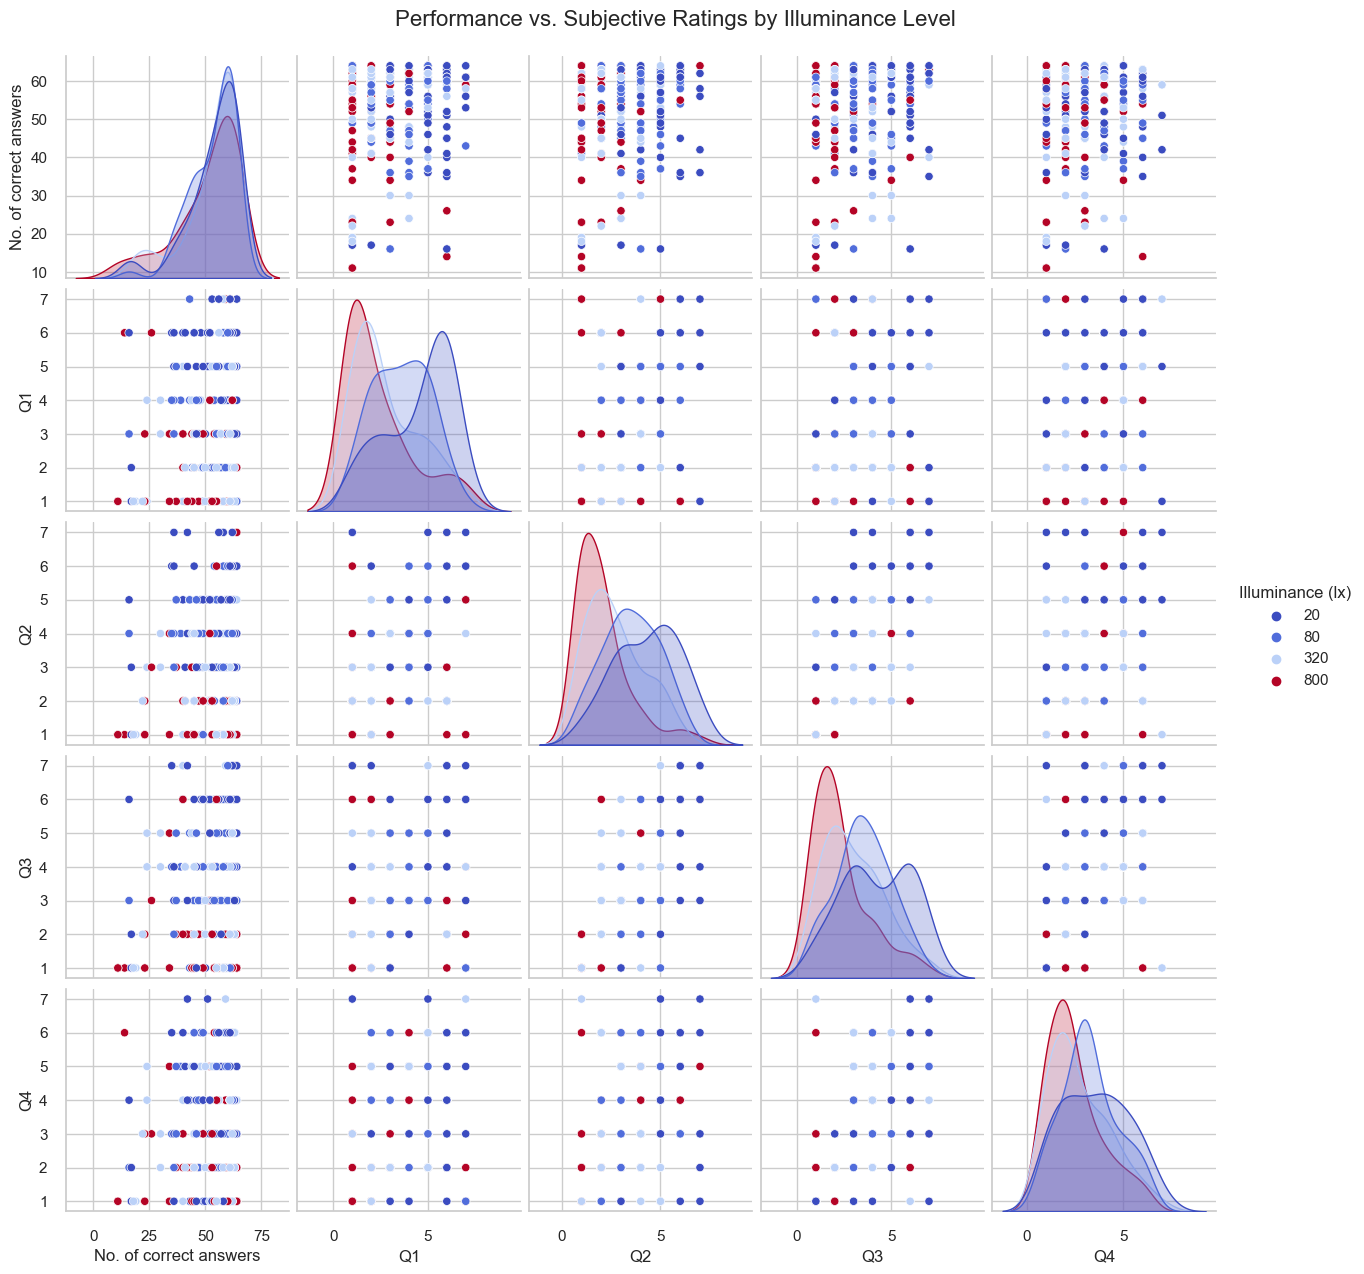

In [81]:
# Pair plot to visualize relationships between performance and subjective ratings by illuminance level
sns.pairplot(df, vars=['No. of correct answers', 'Q1', 'Q2', 'Q3', 'Q4'], hue='Illuminance (lx)', palette='coolwarm')
plt.suptitle('Performance vs. Subjective Ratings by Illuminance Level', y=1.02, fontsize=16)
plt.show()


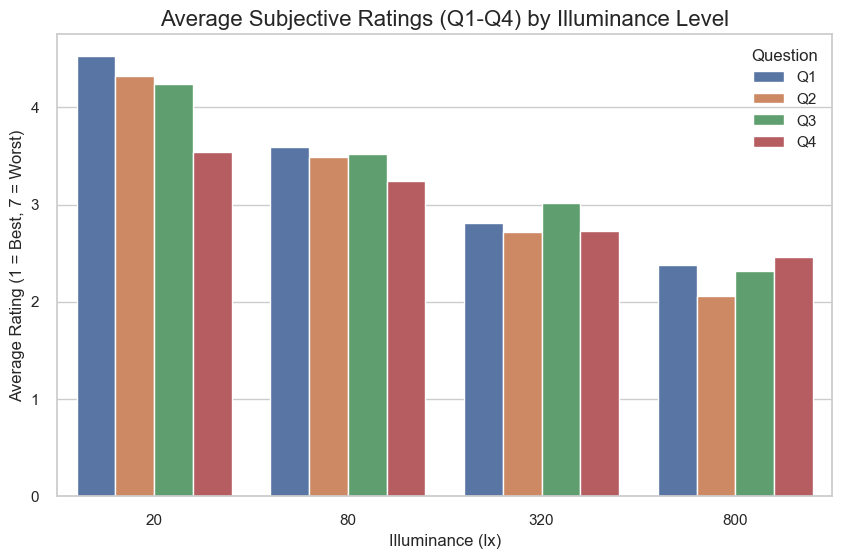

In [82]:
# Calculate mean of subjective ratings for each illuminance level
mean_ratings = df.groupby('Illuminance (lx)')[['Q1', 'Q2', 'Q3', 'Q4']].mean().reset_index()

# Melt the dataframe for easier plotting with seaborn
melted_mean_ratings = mean_ratings.melt(id_vars='Illuminance (lx)', var_name='Question', value_name='Average Rating')

# Grouped bar plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Illuminance (lx)', y='Average Rating', hue='Question', data=melted_mean_ratings)
plt.title('Average Subjective Ratings (Q1-Q4) by Illuminance Level', fontsize=16)
plt.xlabel('Illuminance (lx)', fontsize=12)
plt.ylabel('Average Rating (1 = Best, 7 = Worst)', fontsize=12)
plt.legend(title='Question', loc='upper right')
plt.show()


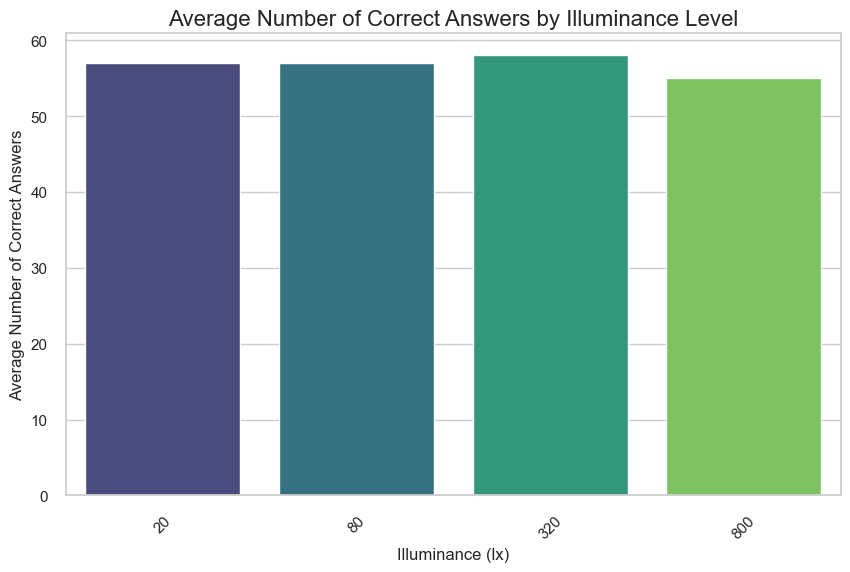

In [88]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# df = pd.read_csv('your_file.csv')  # Uncomment and modify this line to load your data

# Calculate mean of correct answers for each illuminance level
median_performance = df.groupby('Illuminance (lx)')['No. of correct answers'].median().reset_index()

# Bar plot of average number of correct answers by illuminance level
plt.figure(figsize=(10, 6))
sns.barplot(x='Illuminance (lx)', y='No. of correct answers', data=median_performance, palette='viridis')
plt.title('Average Number of Correct Answers by Illuminance Level', fontsize=16)
plt.xlabel('Illuminance (lx)', fontsize=12)
plt.ylabel('Average Number of Correct Answers', fontsize=12)
plt.xticks(rotation=45)  # Rotate x-axis labels if necessary
plt.show()


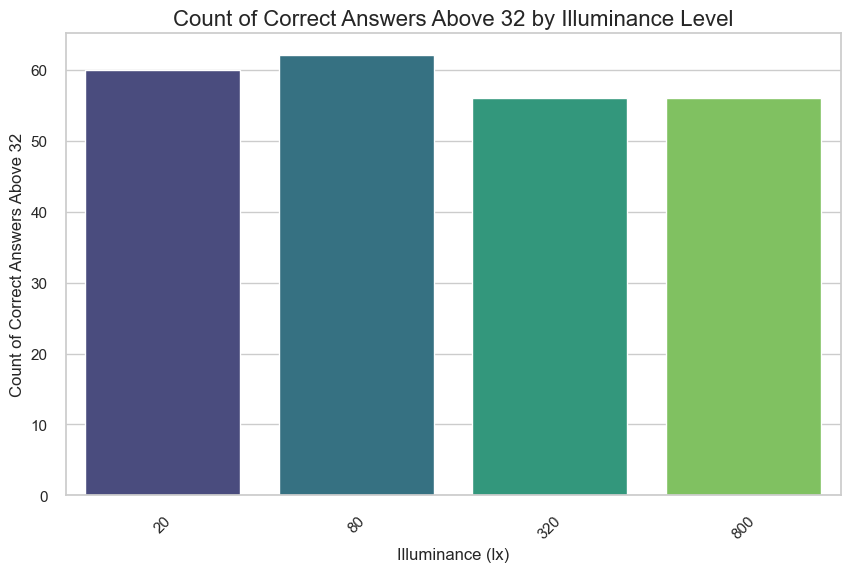

In [89]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# df = pd.read_csv('your_file.csv')  # Uncomment and modify this line to load your data

# Filter the DataFrame to only include correct answers greater than 32
filtered_df = df[df['No. of correct answers'] > 32]

# Count the occurrences of correct answers greater than 32 for each illuminance level
count_performance = filtered_df['Illuminance (lx)'].value_counts().reset_index()
count_performance.columns = ['Illuminance (lx)', 'Count of Correct Answers Above 32']

# Bar plot of the count of correct answers above 32 by illuminance level
plt.figure(figsize=(10, 6))
sns.barplot(x='Illuminance (lx)', y='Count of Correct Answers Above 32', data=count_performance, palette='viridis')
plt.title('Count of Correct Answers Above 32 by Illuminance Level', fontsize=16)
plt.xlabel('Illuminance (lx)', fontsize=12)
plt.ylabel('Count of Correct Answers Above 32', fontsize=12)
plt.xticks(rotation=45)  # Rotate x-axis labels if necessary
plt.show()


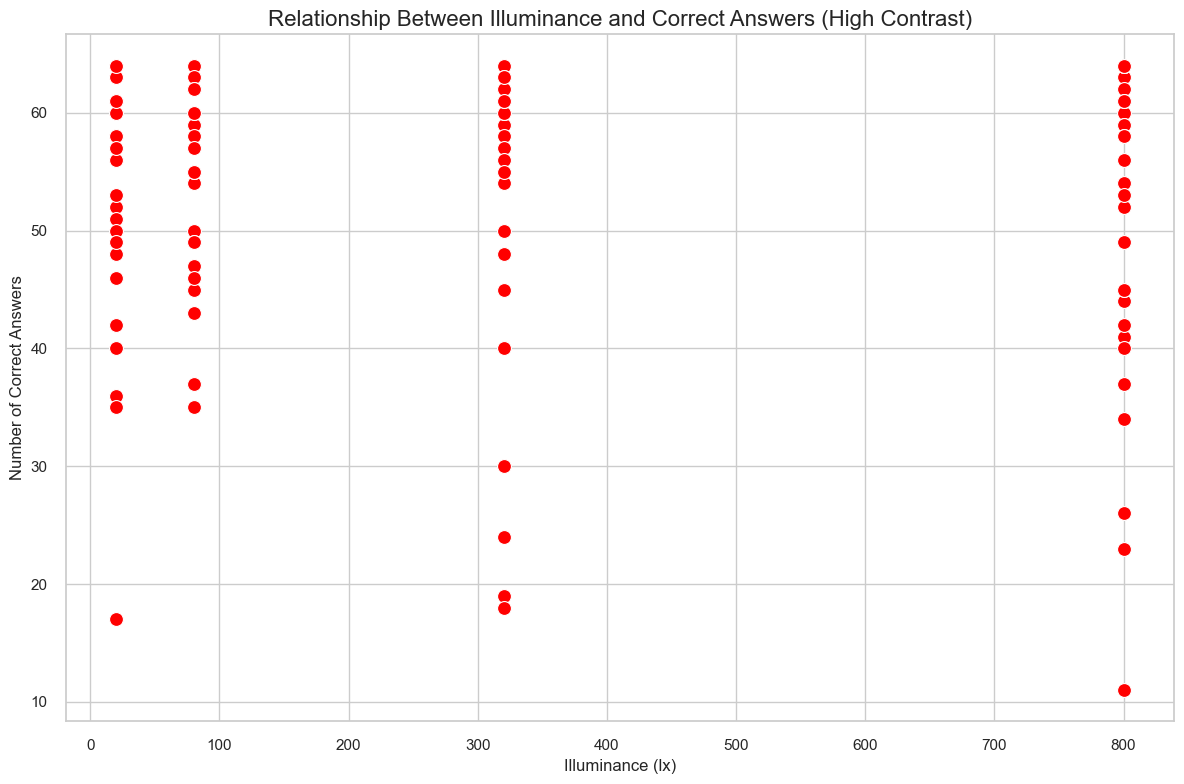

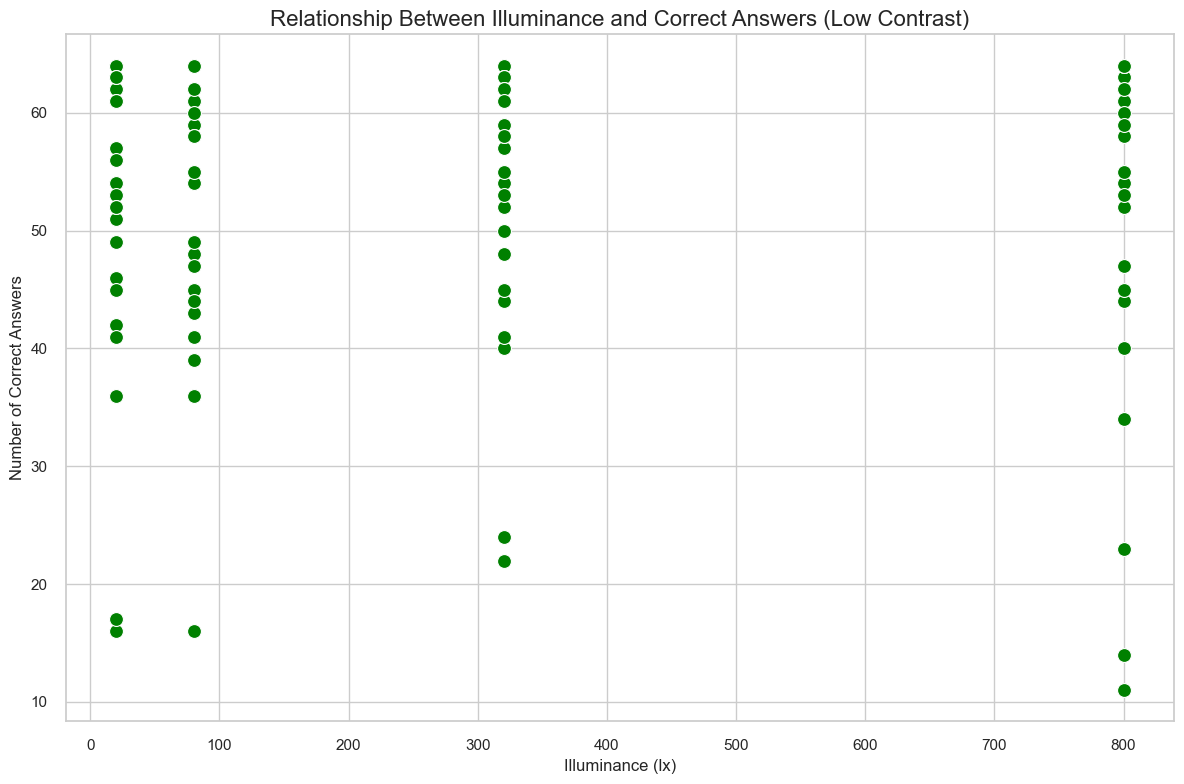

In [90]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# df = pd.read_csv('your_file.csv')  # Uncomment and modify this line to load your data

# Standardize contrast levels
df['Contrast'] = df['Contrast'].str.strip().str.lower()  # Convert to lowercase and strip spaces

# Set the color palette for contrast levels
palette = {'high': 'red', 'low': 'green'}

# Filter data for high and low contrast
df_high = df[df['Contrast'] == 'high']
df_low = df[df['Contrast'] == 'low']

# Create a scatter plot for high contrast
plt.figure(figsize=(12, 8))
sns.scatterplot(data=df_high, 
                 x='Illuminance (lx)', 
                 y='No. of correct answers', 
                 color='red',  # Set color for high contrast
                 s=100)  # Size of markers

plt.title('Relationship Between Illuminance and Correct Answers (High Contrast)', fontsize=16)
plt.xlabel('Illuminance (lx)', fontsize=12)
plt.ylabel('Number of Correct Answers', fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.show()

# Create a scatter plot for low contrast
plt.figure(figsize=(12, 8))
sns.scatterplot(data=df_low, 
                 x='Illuminance (lx)', 
                 y='No. of correct answers', 
                 color='green',  # Set color for low contrast
                 s=100)  # Size of markers

plt.title('Relationship Between Illuminance and Correct Answers (Low Contrast)', fontsize=16)
plt.xlabel('Illuminance (lx)', fontsize=12)
plt.ylabel('Number of Correct Answers', fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.show()


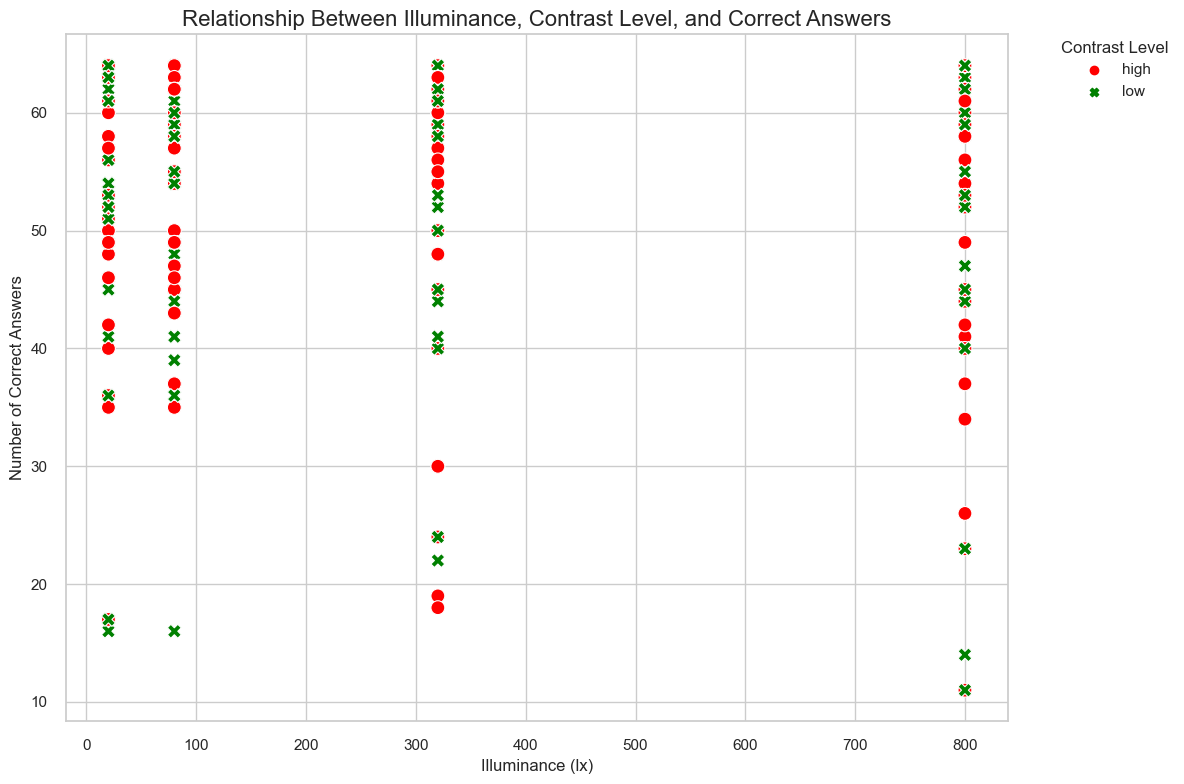

In [91]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# df = pd.read_csv('your_file.csv')  # Uncomment and modify this line to load your data

# Standardize contrast levels
df['Contrast'] = df['Contrast'].str.strip().str.lower()  # Convert to lowercase and strip spaces

# Set the color palette for contrast levels
palette = {'high': 'red', 'low': 'green'}

# Create a scatter plot
plt.figure(figsize=(12, 8))
sns.scatterplot(data=df, 
                 x='Illuminance (lx)', 
                 y='No. of correct answers', 
                 hue='Contrast',  # Use the contrast level for color
                 palette=palette, 
                 style='Contrast',  # Optional: use different markers for contrast
                 s=100)  # Size of markers

plt.title('Relationship Between Illuminance, Contrast Level, and Correct Answers', fontsize=16)
plt.xlabel('Illuminance (lx)', fontsize=12)
plt.ylabel('Number of Correct Answers', fontsize=12)

# Move legend outside the plot
plt.legend(title='Contrast Level', bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)

plt.grid(True)
plt.tight_layout()  # Adjust layout to make room for the legend
plt.show()


C:\Users\Haritha\AppData\Local\Temp\ipykernel_2380\3689967708.py:40: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r--" (-> color='r'). The keyword argument will take precedence.
  plt.plot(x, p(x), "r--", color='green')


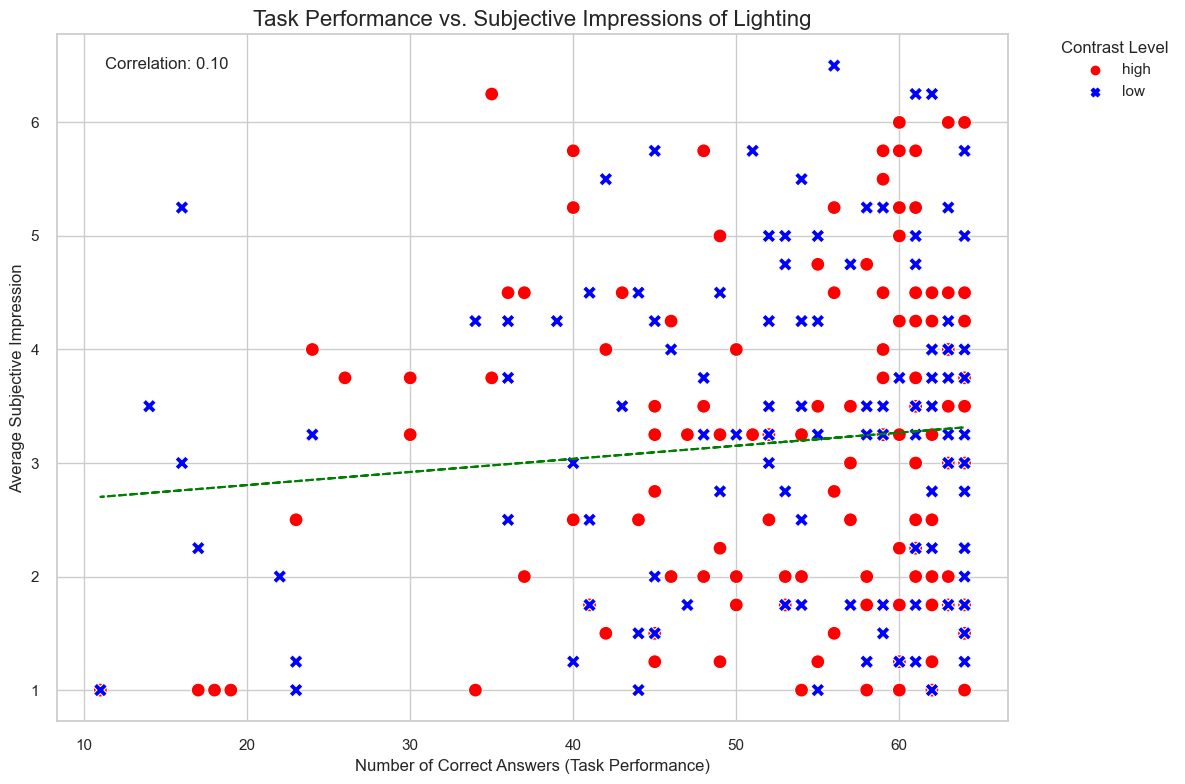

Correlation between task performance and subjective impressions: 0.10
R-squared: 0.01
P-value: 0.1270


In [96]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

# Assuming df is already loaded with your dataset

# Calculate average subjective impression
df['Avg_Subjective'] = df[['Q1', 'Q2', 'Q3', 'Q4']].mean(axis=1)

# Standardize contrast levels
df['Contrast'] = df['Contrast'].str.strip().str.lower()

# Set the color palette for contrast levels
palette = {'high': 'red', 'low': 'blue'}

# Create a scatter plot
plt.figure(figsize=(12, 8))
sns.scatterplot(data=df, 
                x='No. of correct answers',  # Use the exact column name
                y='Avg_Subjective', 
                hue='Contrast',
                palette=palette, 
                style='Contrast',
                s=100)

plt.title('Task Performance vs. Subjective Impressions of Lighting', fontsize=16)
plt.xlabel('Number of Correct Answers (Task Performance)', fontsize=12)
plt.ylabel('Average Subjective Impression', fontsize=12)

# Move legend outside the plot
plt.legend(title='Contrast Level', bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)

# Add a trend line
x = df['No. of correct answers']
y = df['Avg_Subjective']
z = np.polyfit(x, y, 1)
p = np.poly1d(z)
plt.plot(x, p(x), "r--", color='green')

# Calculate correlation coefficient
correlation = df['No. of correct answers'].corr(df['Avg_Subjective'])
plt.text(0.05, 0.95, f'Correlation: {correlation:.2f}', transform=plt.gca().transAxes)

plt.tight_layout()
plt.show()

# Additional analysis
print(f"Correlation between task performance and subjective impressions: {correlation:.2f}")

# Perform a simple linear regression
slope, intercept, r_value, p_value, std_err = stats.linregress(df['No. of correct answers'], df['Avg_Subjective'])
print(f"R-squared: {r_value**2:.2f}")
print(f"P-value: {p_value:.4f}")



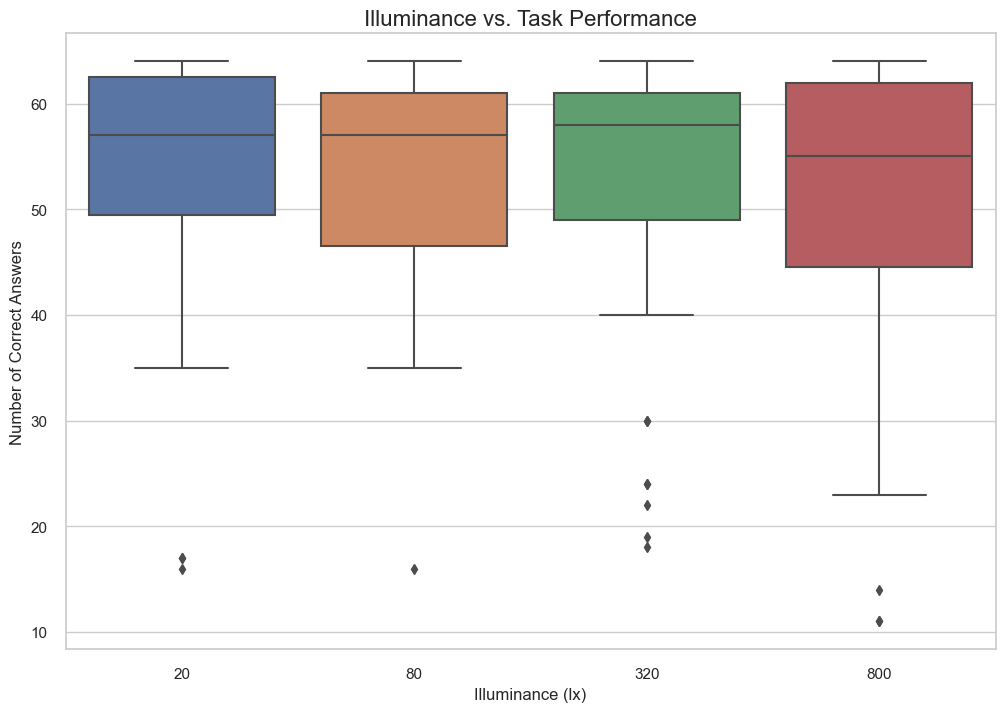

In [97]:
# Analyze the relationship between illuminance and task performance
plt.figure(figsize=(12, 8))
sns.boxplot(x='Illuminance (lx)', y='No. of correct answers', data=df)
plt.title('Illuminance vs. Task Performance', fontsize=16)
plt.xlabel('Illuminance (lx)', fontsize=12)
plt.ylabel('Number of Correct Answers', fontsize=12)
plt.show()



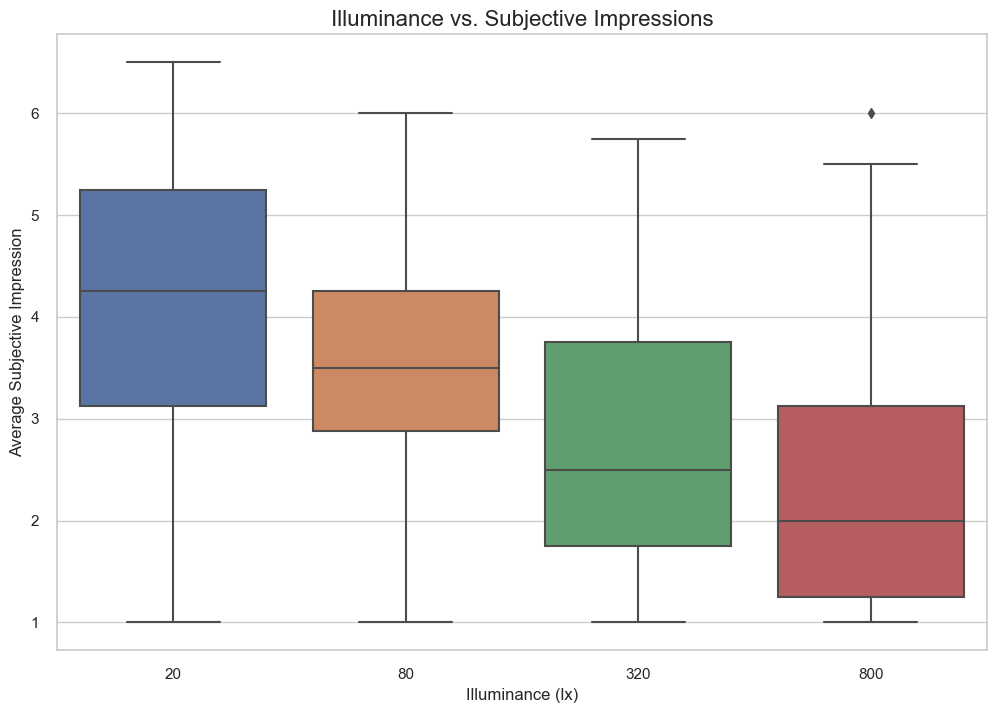

In [98]:
# Analyze the relationship between illuminance and subjective impressions
plt.figure(figsize=(12, 8))
sns.boxplot(x='Illuminance (lx)', y='Avg_Subjective', data=df)
plt.title('Illuminance vs. Subjective Impressions', fontsize=16)
plt.xlabel('Illuminance (lx)', fontsize=12)
plt.ylabel('Average Subjective Impression', fontsize=12)
plt.show()

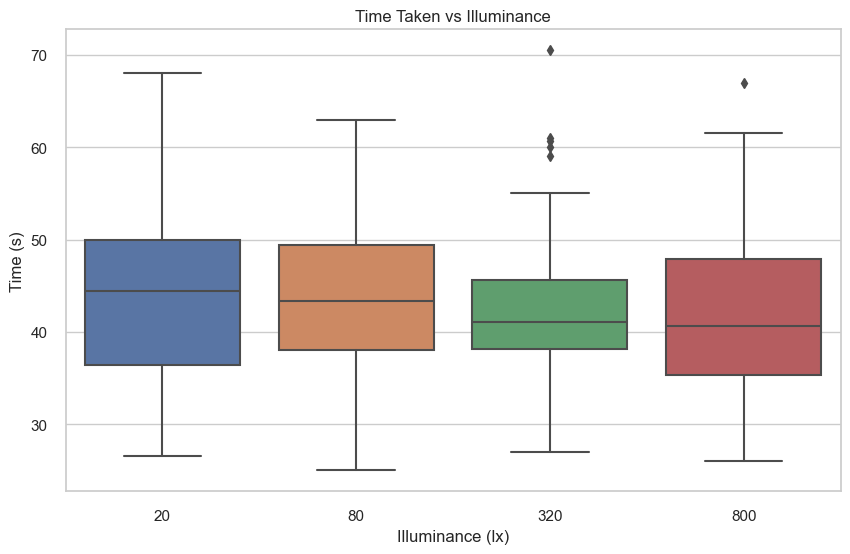

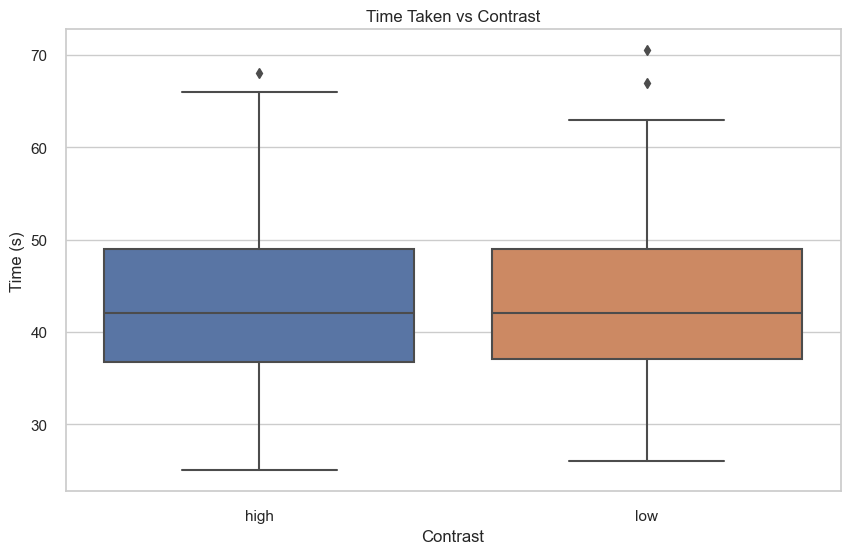

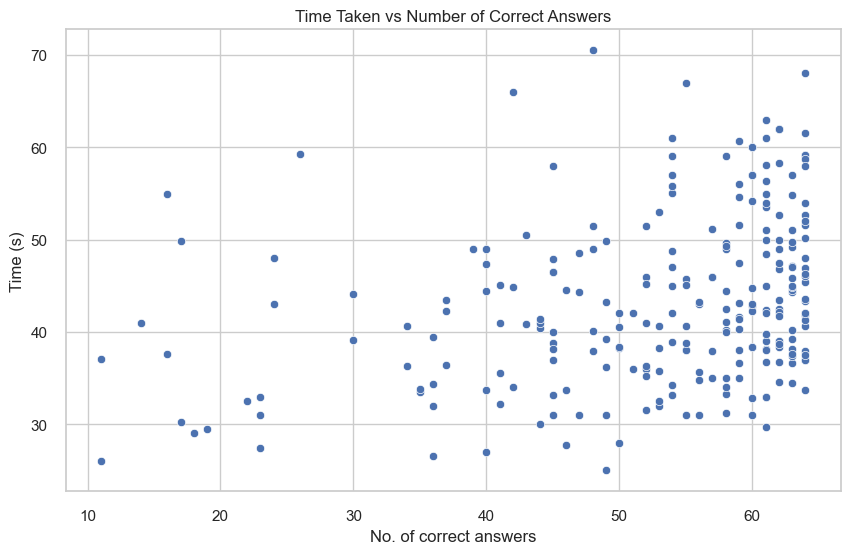

Correlations between Time and Subjective Metrics:
Q1    0.177432
Q2    0.239391
Q3    0.187367
Q4    0.214105
Name: Time (s), dtype: float64


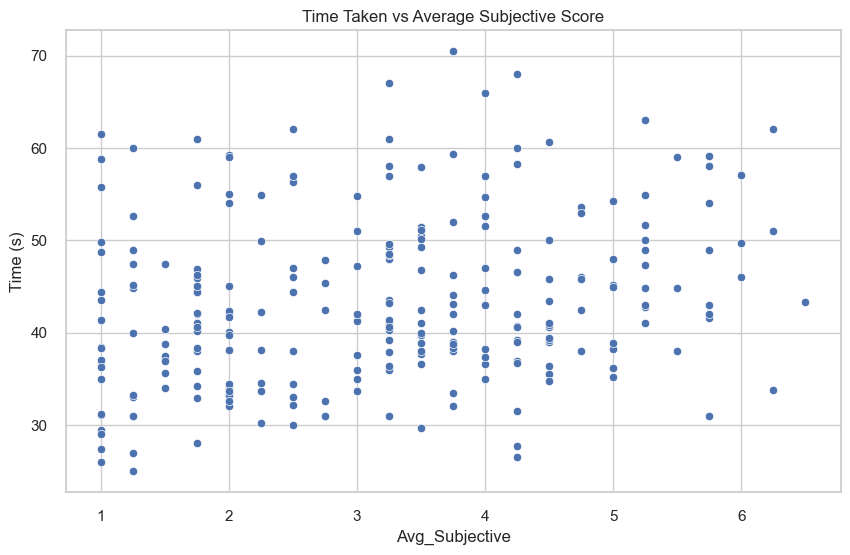

                            OLS Regression Results                            
Dep. Variable:               Time (s)   R-squared:                       0.131
Model:                            OLS   Adj. R-squared:                  0.121
Method:                 Least Squares   F-statistic:                     12.46
Date:                Sat, 12 Oct 2024   Prob (F-statistic):           1.28e-07
Time:                        22:41:44   Log-Likelihood:                -893.65
No. Observations:                 252   AIC:                             1795.
Df Residuals:                     248   BIC:                             1809.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     27

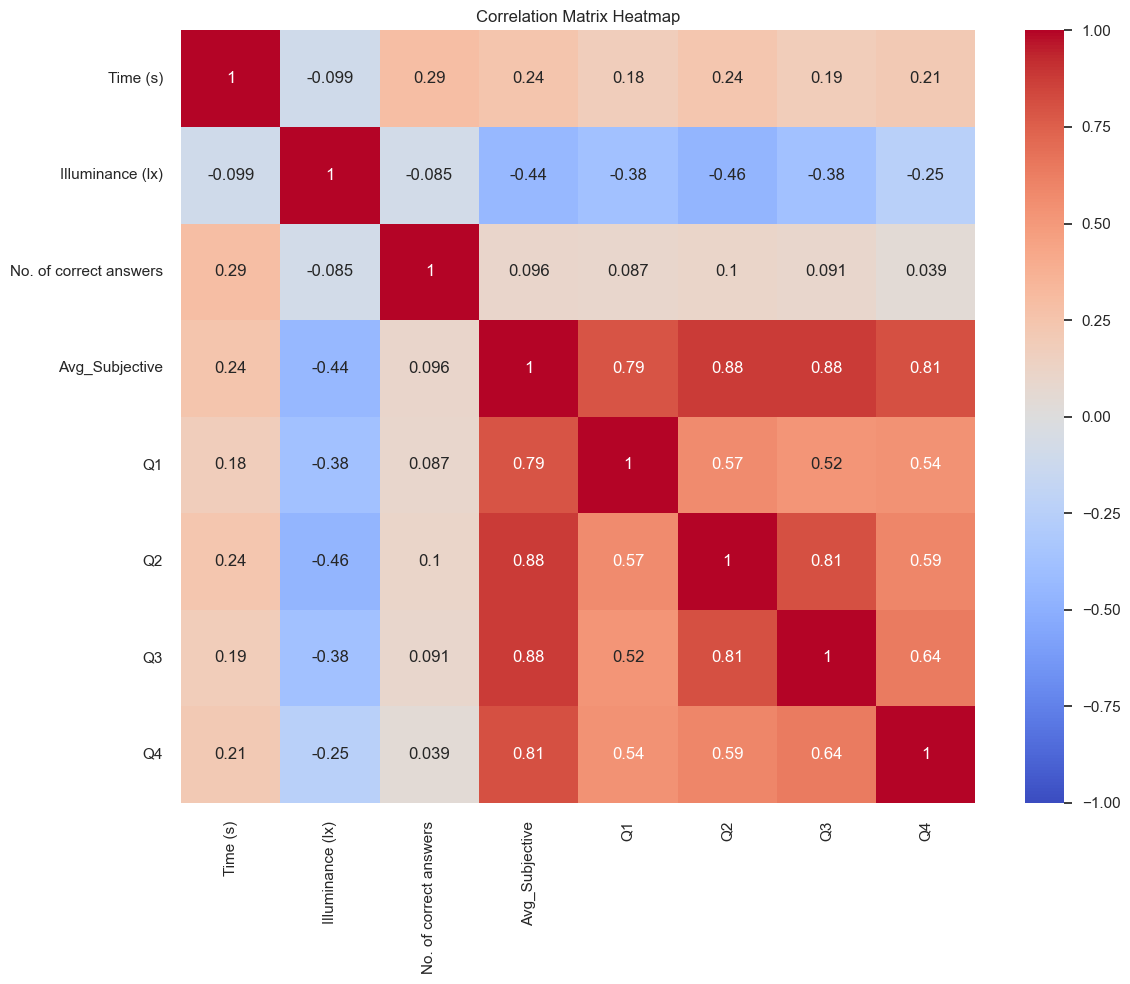

In [100]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
import statsmodels.api as sm

# Assuming df is your DataFrame with the data

# 1. Time vs Illuminance
plt.figure(figsize=(10, 6))
sns.boxplot(x='Illuminance (lx)', y='Time (s)', data=df)
plt.title('Time Taken vs Illuminance')
plt.show()

# 2. Time vs Contrast
plt.figure(figsize=(10, 6))
sns.boxplot(x='Contrast', y='Time (s)', data=df)
plt.title('Time Taken vs Contrast')
plt.show()

# 3. Time vs Number of Correct Answers
plt.figure(figsize=(10, 6))
sns.scatterplot(x='No. of correct answers', y='Time (s)', data=df)
plt.title('Time Taken vs Number of Correct Answers')
plt.show()

# 4. Correlation between Time and Subjective Metrics
subjective_metrics = ['Q1', 'Q2', 'Q3', 'Q4']
correlations = df[['Time (s)'] + subjective_metrics].corr()['Time (s)'][1:]
print("Correlations between Time and Subjective Metrics:")
print(correlations)

# 5. Time vs Average Subjective Score
df['Avg_Subjective'] = df[subjective_metrics].mean(axis=1)
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Avg_Subjective', y='Time (s)', data=df)
plt.title('Time Taken vs Average Subjective Score')
plt.show()

# 6. Multiple regression
X = df[['Illuminance (lx)', 'No. of correct answers', 'Avg_Subjective']]
X = sm.add_constant(X)
y = df['Time (s)']
model = sm.OLS(y, X).fit()
print(model.summary())

# 7. Correlation matrix heatmap
plt.figure(figsize=(12, 10))
correlation_matrix = df[['Time (s)', 'Illuminance (lx)', 'No. of correct answers', 'Avg_Subjective'] + subjective_metrics].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Correlation Matrix Heatmap')
plt.tight_layout()
plt.show()

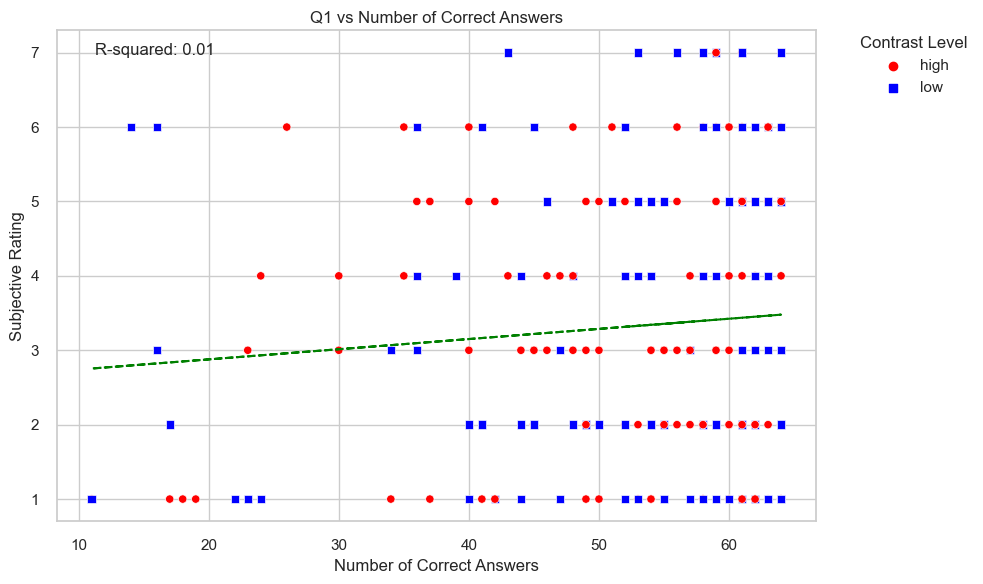

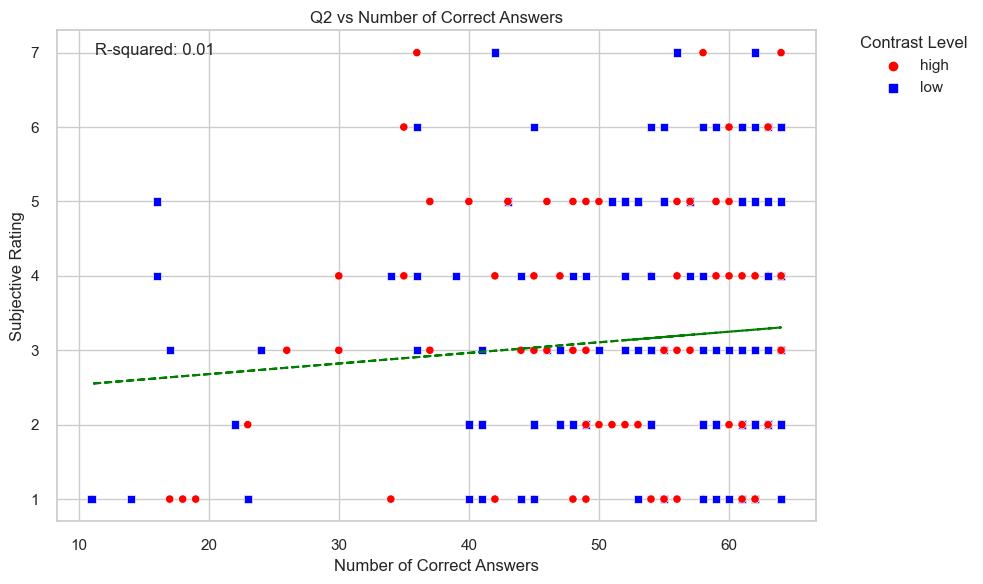

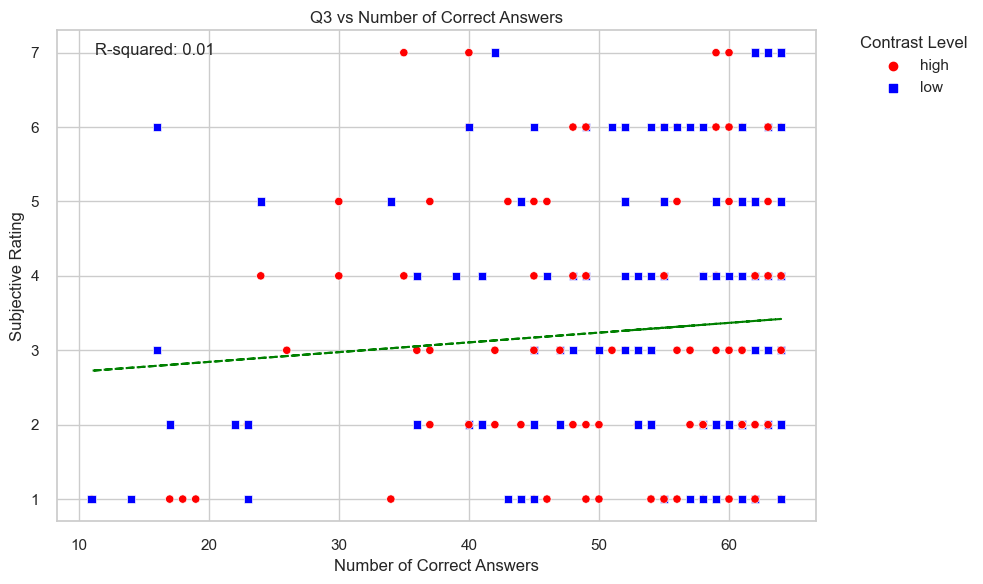

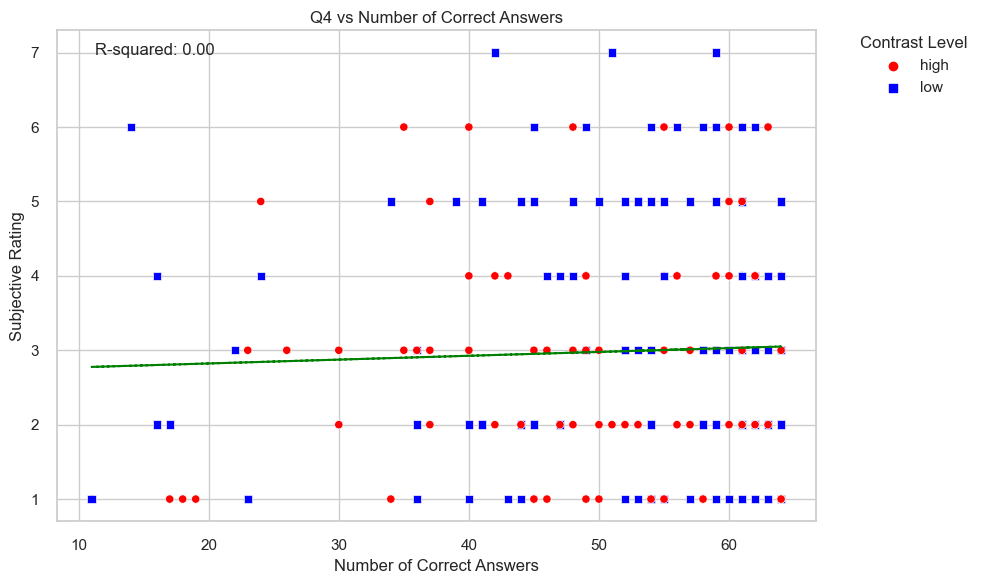

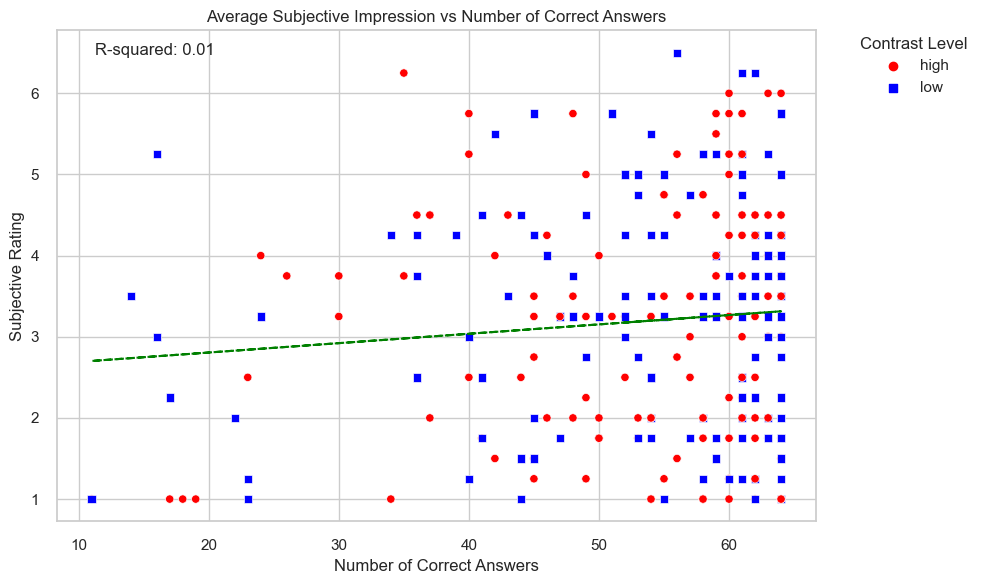

In [103]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

# Create a function to plot scatter and regression line with legend outside
def plot_scatter_regression(x, y, contrast, title):
    plt.figure(figsize=(10, 6))
    
    # Scatter plot
    sns.scatterplot(x=x, y=y, hue=contrast, style=contrast, 
                    palette={'high': 'red', 'low': 'blue'}, 
                    markers={'high': 'o', 'low': 's'})
    
    # Regression line
    slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
    line = slope * np.array(x) + intercept
    plt.plot(x, line, color='green', linestyle='--')
    
    plt.title(title)
    plt.xlabel('Number of Correct Answers')
    plt.ylabel('Subjective Rating')
    
    # Add R-squared value to the plot
    plt.text(0.05, 0.95, f'R-squared: {r_value**2:.2f}', transform=plt.gca().transAxes)
    
    # Move legend outside the plot
    plt.legend(title='Contrast Level', bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)

    plt.tight_layout()
    plt.show()

# Standardize contrast levels
df['Contrast'] = df['Contrast'].str.strip().str.lower()

# Create scatter plots for Q1, Q2, Q3, Q4
for q in ['Q1', 'Q2', 'Q3', 'Q4']:
    plot_scatter_regression(df['No. of correct answers'], df[q], df['Contrast'], 
                            f'{q} vs Number of Correct Answers')

# Create scatter plot for average subjective impression
df['Avg_Subjective'] = df[['Q1', 'Q2', 'Q3', 'Q4']].mean(axis=1)
plot_scatter_regression(df['No. of correct answers'], df['Avg_Subjective'], df['Contrast'], 
                        'Average Subjective Impression vs Number of Correct Answers')

Effect of Illuminance on Objective Performance:
F-statistic: 0.6153867833279434, p-value: 0.6056178109663125

Effect of Contrast on Objective Performance:
T-statistic: -0.2756301734974753, p-value: 0.7830598196748313

Effect of Landolt C Test Variation on Objective Performance:
F-statistic: 0.9964268478799998, p-value: 0.43439413329690557


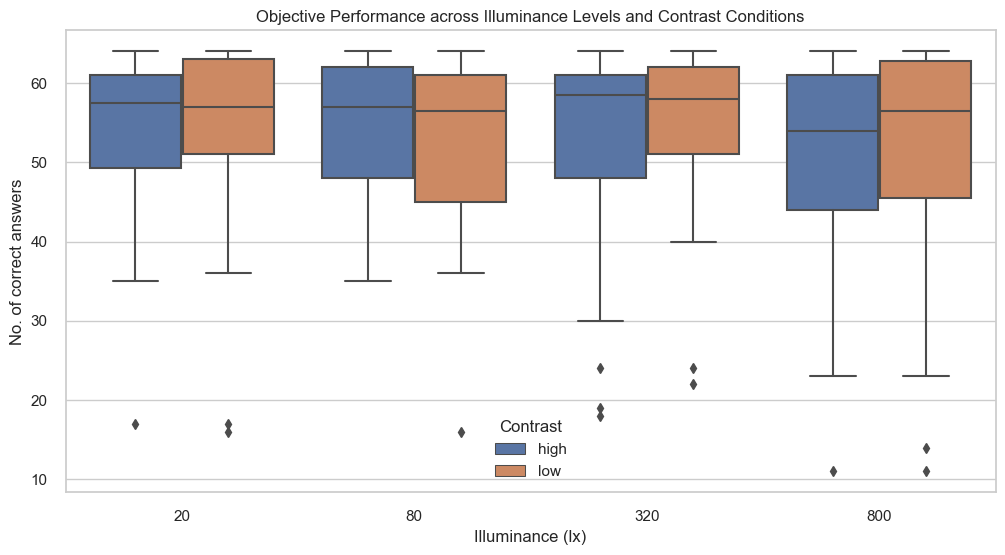

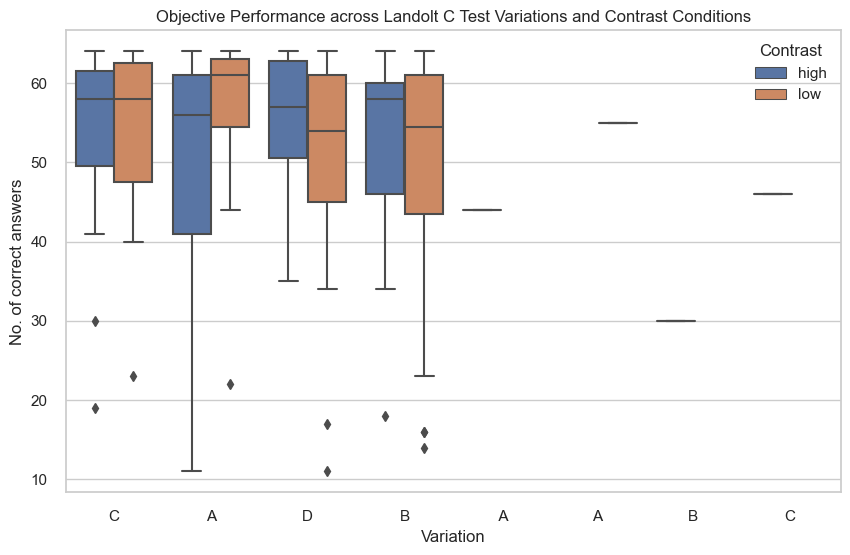


Correlation between Objective Performance and Average Subjective Rating: 0.09639060679321469


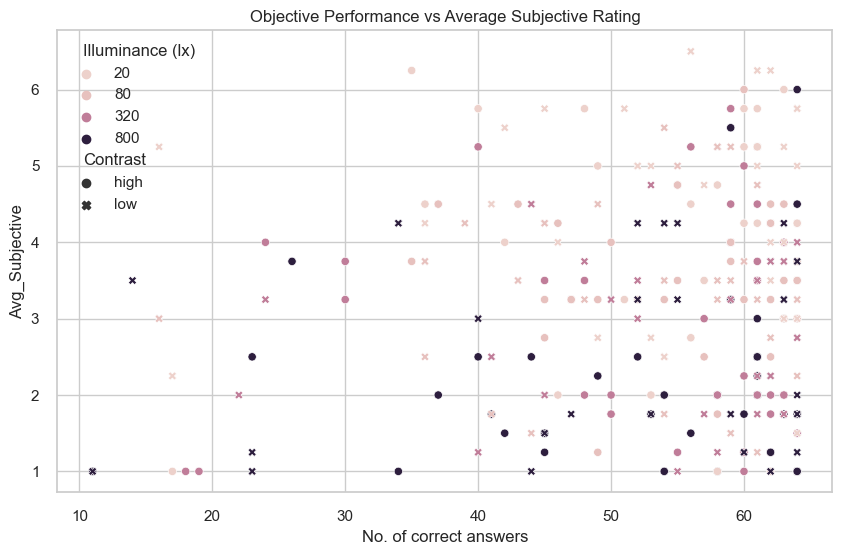

In [105]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming the data is in a DataFrame called 'df'
df['Contrast'] = df['Contrast'].str.lower()  # Make contrast case-insensitive
df['Variation'] = df['Variation'].str.upper()  # Make variation case-insensitive

# Analyze effect of illuminance on objective performance
illuminance_groups = df.groupby('Illuminance (lx)')['No. of correct answers']
illuminance_means = illuminance_groups.mean()
f_statistic, p_value = stats.f_oneway(*[group for name, group in illuminance_groups])

print("Effect of Illuminance on Objective Performance:")
print(f"F-statistic: {f_statistic}, p-value: {p_value}")

# Analyze effect of contrast on objective performance
contrast_groups = df.groupby('Contrast')['No. of correct answers']
t_statistic, p_value = stats.ttest_ind(contrast_groups.get_group('high'), contrast_groups.get_group('low'))

print("\nEffect of Contrast on Objective Performance:")
print(f"T-statistic: {t_statistic}, p-value: {p_value}")

# Analyze effect of Landolt C test variation on objective performance
variation_groups = df.groupby('Variation')['No. of correct answers']
f_statistic, p_value = stats.f_oneway(*[group for name, group in variation_groups])

print("\nEffect of Landolt C Test Variation on Objective Performance:")
print(f"F-statistic: {f_statistic}, p-value: {p_value}")

# Visualize the results
plt.figure(figsize=(12, 6))
sns.boxplot(x='Illuminance (lx)', y='No. of correct answers', hue='Contrast', data=df)
plt.title('Objective Performance across Illuminance Levels and Contrast Conditions')
plt.show()

# Visualize performance across Landolt C test variations
plt.figure(figsize=(10, 6))
sns.boxplot(x='Variation', y='No. of correct answers', hue='Contrast', data=df)
plt.title('Objective Performance across Landolt C Test Variations and Contrast Conditions')
plt.show()

# Analyze subjective ratings
subjective_metrics = ['Q1', 'Q2', 'Q3', 'Q4']
df['Avg_Subjective'] = df[subjective_metrics].mean(axis=1)

# Correlation between objective performance and subjective ratings
correlation = df['No. of correct answers'].corr(df['Avg_Subjective'])
print(f"\nCorrelation between Objective Performance and Average Subjective Rating: {correlation}")

# Visualize relationship between objective performance and subjective ratings
plt.figure(figsize=(10, 6))
sns.scatterplot(x='No. of correct answers', y='Avg_Subjective', hue='Illuminance (lx)', style='Contrast', data=df)
plt.title('Objective Performance vs Average Subjective Rating')
plt.show()

Effect of Illuminance on Objective Performance:
F-statistic: 0.6153867833279434, p-value: 0.6056178109663125

Effect of Contrast on Objective Performance:
T-statistic: -0.2756301734974753, p-value: 0.7830598196748313

Effect of Landolt C Test Variation on Objective Performance:
F-statistic: 0.8364011050499308, p-value: 0.4750215571739942


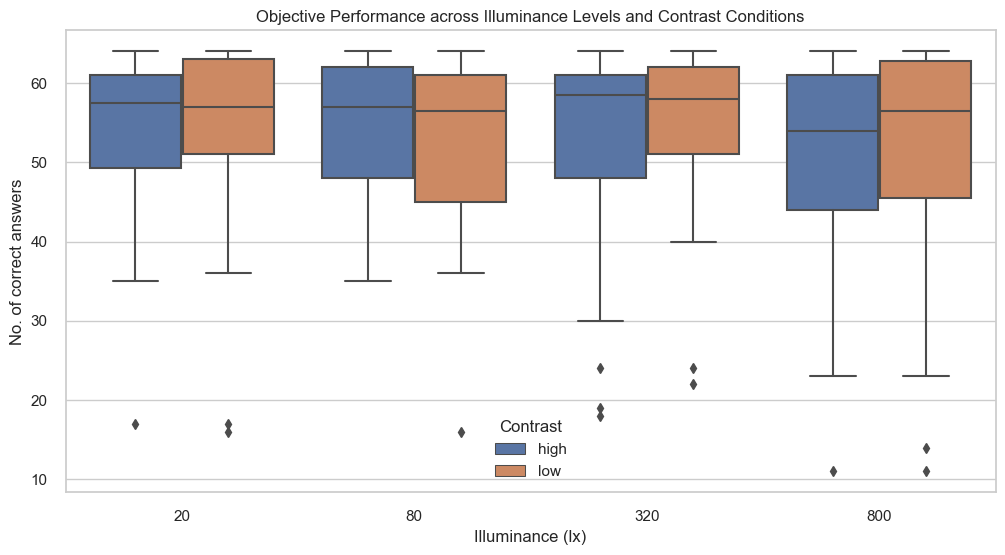

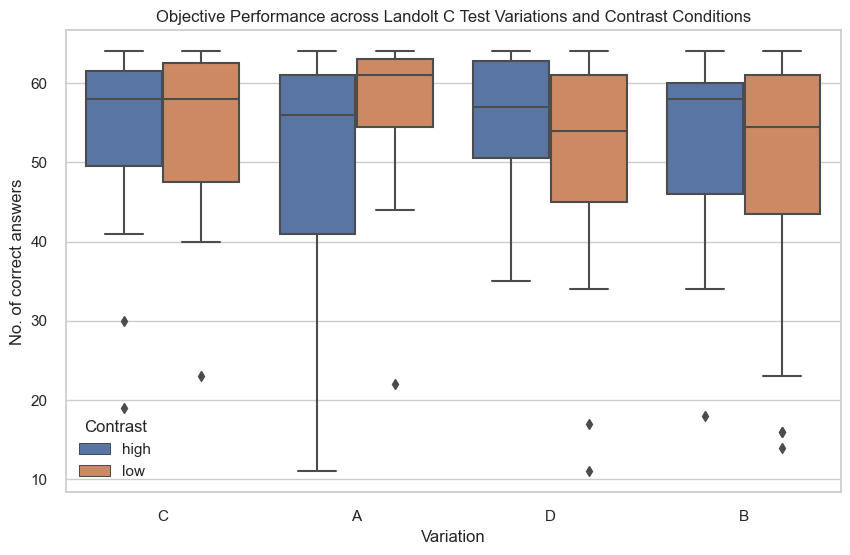


Correlation between Objective Performance and Average Subjective Rating: 0.09639060679321469


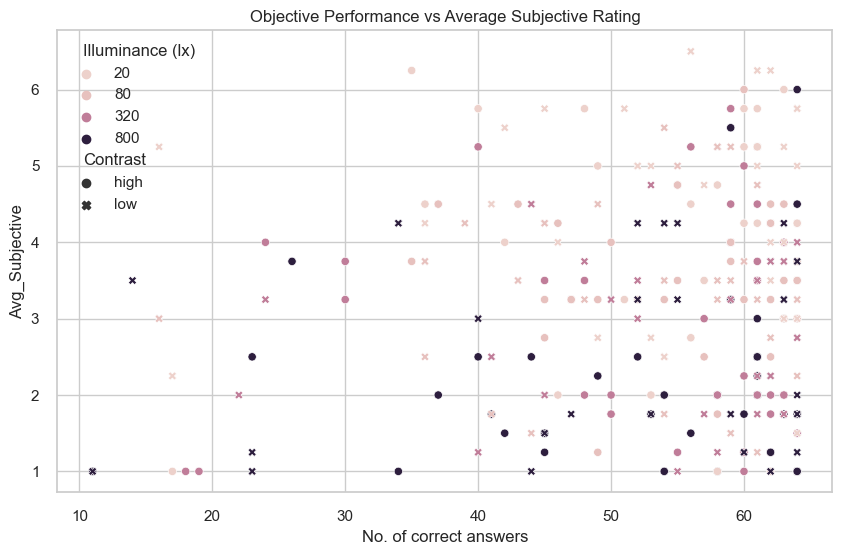

In [106]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming the data is in a DataFrame called 'df'
df['Contrast'] = df['Contrast'].str.lower()  # Make contrast case-insensitive
df['Variation'] = df['Variation'].str.upper()  # Make variation uppercase

# Ensure Variation only contains A, B, C, or D
df['Variation'] = df['Variation'].apply(lambda x: x if x in ['A', 'B', 'C', 'D'] else np.nan)

# Analyze effect of illuminance on objective performance
illuminance_groups = df.groupby('Illuminance (lx)')['No. of correct answers']
f_statistic, p_value = stats.f_oneway(*[group for name, group in illuminance_groups])

print("Effect of Illuminance on Objective Performance:")
print(f"F-statistic: {f_statistic}, p-value: {p_value}")

# Analyze effect of contrast on objective performance
contrast_groups = df.groupby('Contrast')['No. of correct answers']
t_statistic, p_value = stats.ttest_ind(contrast_groups.get_group('high'), contrast_groups.get_group('low'))

print("\nEffect of Contrast on Objective Performance:")
print(f"T-statistic: {t_statistic}, p-value: {p_value}")

# Analyze effect of Landolt C test variation on objective performance
variation_groups = df.groupby('Variation')['No. of correct answers']
f_statistic, p_value = stats.f_oneway(*[group for name, group in variation_groups])

print("\nEffect of Landolt C Test Variation on Objective Performance:")
print(f"F-statistic: {f_statistic}, p-value: {p_value}")

# Visualize the results
plt.figure(figsize=(12, 6))
sns.boxplot(x='Illuminance (lx)', y='No. of correct answers', hue='Contrast', data=df)
plt.title('Objective Performance across Illuminance Levels and Contrast Conditions')
plt.show()

# Visualize performance across Landolt C test variations
plt.figure(figsize=(10, 6))
sns.boxplot(x='Variation', y='No. of correct answers', hue='Contrast', data=df)
plt.title('Objective Performance across Landolt C Test Variations and Contrast Conditions')
plt.show()

# Analyze subjective ratings
subjective_metrics = ['Q1', 'Q2', 'Q3', 'Q4']
df['Avg_Subjective'] = df[subjective_metrics].mean(axis=1)

# Correlation between objective performance and subjective ratings
correlation = df['No. of correct answers'].corr(df['Avg_Subjective'])
print(f"\nCorrelation between Objective Performance and Average Subjective Rating: {correlation}")

# Visualize relationship between objective performance and subjective ratings
plt.figure(figsize=(10, 6))
sns.scatterplot(x='No. of correct answers', y='Avg_Subjective', hue='Illuminance (lx)', style='Contrast', data=df)
plt.title('Objective Performance vs Average Subjective Rating')
plt.show()

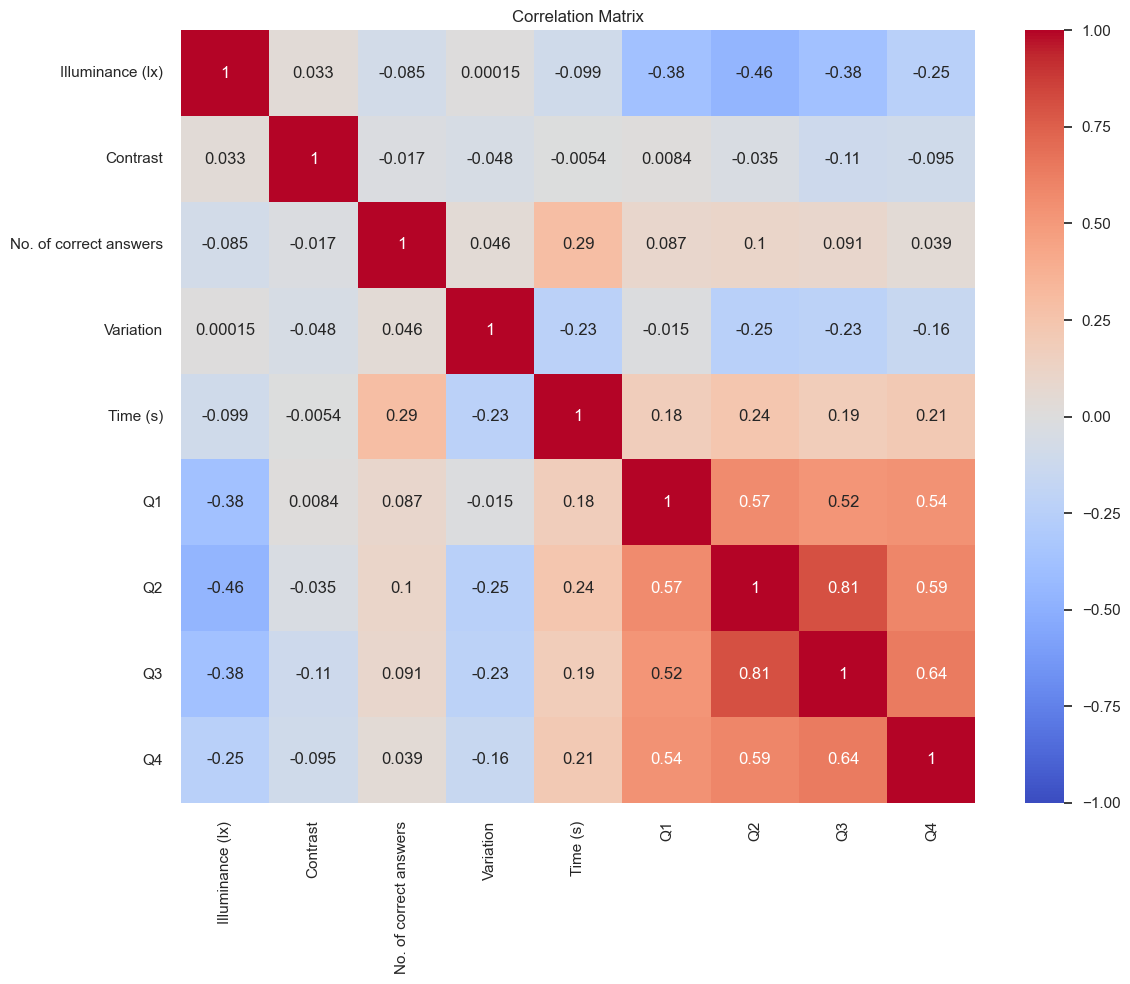

                        Illuminance (lx)  Contrast  No. of correct answers  \
Illuminance (lx)                1.000000  0.033344               -0.084588   
Contrast                        0.033344  1.000000               -0.017430   
No. of correct answers         -0.084588 -0.017430                1.000000   
Variation                       0.000150 -0.047535                0.046420   
Time (s)                       -0.098705 -0.005448                0.290138   
Q1                             -0.377860  0.008412                0.087356   
Q2                             -0.461631 -0.035373                0.102169   
Q3                             -0.378961 -0.111959                0.091177   
Q4                             -0.246447 -0.095371                0.039431   

                        Variation  Time (s)        Q1        Q2        Q3  \
Illuminance (lx)         0.000150 -0.098705 -0.377860 -0.461631 -0.378961   
Contrast                -0.047535 -0.005448  0.008412 -0.035373 -

In [107]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming the data is already in a DataFrame called df
# If not, you would need to load it first

# Convert categorical variables to numeric
df['Contrast'] = df['Contrast'].map({'low': 0, 'high': 1})
df['Variation'] = df['Variation'].map({'A': 0, 'B': 1, 'C': 2, 'D': 3})

# Select the columns for correlation
columns_for_correlation = ['Illuminance (lx)', 'Contrast', 'No. of correct answers', 'Variation', 'Time (s)', 'Q1', 'Q2', 'Q3', 'Q4']

# Create the correlation matrix
correlation_matrix = df[columns_for_correlation].corr()

# Create a heatmap of the correlation matrix
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

# Print the correlation matrix
print(correlation_matrix)